# 1. 데이터 전처리
## 1-1. 라이브러리 불러오기

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

from imblearn.pipeline import Pipeline      # SMOTE를 넣으려면 imblearn의 Pipeline 사용
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42

## 1-2. 데이터 통계치 확인

In [3]:
import pandas as pd

df = pd.read_csv('./bank-full.csv', sep=';')
print('\n데이터 행 열 개수')
print(df.shape)
print('\n데이터 숫자 통계치')
print(df.describe(include='all'))
print('\n칼럼명 확인')
print(df.columns.tolist())
print('\n칼럼별 결측치 확인')
print(df.isnull().sum())
print('\n중복 데이터 확인')
print(df.duplicated().sum())


데이터 행 열 개수
(45211, 17)

데이터 숫자 통계치
                 age          job  marital  education default        balance  \
count   45211.000000        45211    45211      45211   45211   45211.000000   
unique           NaN           12        3          4       2            NaN   
top              NaN  blue-collar  married  secondary      no            NaN   
freq             NaN         9732    27214      23202   44396            NaN   
mean       40.936210          NaN      NaN        NaN     NaN    1362.272058   
std        10.618762          NaN      NaN        NaN     NaN    3044.765829   
min        18.000000          NaN      NaN        NaN     NaN   -8019.000000   
25%        33.000000          NaN      NaN        NaN     NaN      72.000000   
50%        39.000000          NaN      NaN        NaN     NaN     448.000000   
75%        48.000000          NaN      NaN        NaN     NaN    1428.000000   
max        95.000000          NaN      NaN        NaN     NaN  102127.000000   

   

## 1-3. unknown 현황 확인(건수, 비율)

In [4]:
# unknown 현황 다시 확인
unknown_cols = ['job', 'education', 'contact', 'poutcome']
for col in unknown_cols:
    print(f"{col}: {(df[col] == 'unknown').sum()}건 ({(df[col] == 'unknown').mean()*100:.2f}%)")

# contact unknown이 특정 월에 몰려 있는지 확인
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
contact_unknown = pd.DataFrame({
    '월별 unknown 비율(%)': (df['contact'] == 'unknown').groupby(df['month']).mean().mul(100).round(1),
    'unknown 중 해당 월 비중(%)': df.loc[df['contact'] == 'unknown', 'month'].value_counts(normalize=True).mul(100).round(1),
}).reindex(month_order)
contact_unknown

job: 288건 (0.64%)
education: 1857건 (4.11%)
contact: 13020건 (28.80%)
poutcome: 36959건 (81.75%)


,월별 unknown 비율(%),unknown 중 해당 월 비중(%)
month,,
jan,0.6,0.1
feb,0.5,0.1
mar,1.5,0.1
apr,0.2,0.0
may,57.9,61.3
jun,84.9,34.8
jul,4.0,2.1
aug,0.8,0.4
sep,8.1,0.4


#### contact unknown 월별 분포
- contact unknown의 96%가 5·6월에 몰려 있고, 6월은 84.9%가 unknown임 (나머지 달은 0.2~8.1%)
- 특정 기간에 연락 방식이 기록되지 않은 것으로 판단되어, 행 삭제나 대체 대신 'unknown'을 하나의 범주로 유지함

## 1-4. 데이터 중복치 탐지 및 X, y 분리

- duration 칼럼이 데이터 누수를 발생시키기 때문에 모델링 과정에서 제외함.
- duration 칼럼 제외 후 중복 건수가 16건(전체의 약 0.035%) 발생함.
- 비율은 매우 작지만, 동일한 행이 Train과 Test에 나뉘어 들어가는 누수를 막기 위해 분할 전에 제거함.
- 이 셀에서 X, y를 만들기 때문에 반드시 1-5(분할)보다 먼저 실행해야 함.
- 참고: 완전히 같은 행은 아니지만 같은 고객이 여러 캠페인에 걸쳐 반복 등장하는 경우도 확인됨. 현재 단계에서는 duration 제거로 생긴 중복만 처리하고, 반복 고객 문제는 추후 모델 평가에서 문제가 될 경우 고객 단위 분할 등으로 고려함.

In [5]:
df = pd.read_csv('bank-full.csv', sep=';')

df = df.drop(columns=['duration'])
print('중복 건수:', df.duplicated().sum())   # 16

df = df.drop_duplicates().reset_index(drop=True)
print('제거 후 shape:', df.shape)            # (45195, 16)

X = df.drop(columns=['y'])
y = (df['y'] == 'yes').astype(int)

중복 건수: 16
제거 후 shape: (45195, 16)


## 1-5. 데이터 분할 및 결측치 전처리
#### job은 행 삭제
#### education은 직업별 최빈값 대체 (Train 기준 계산 → Val·Test에 동일 적용)

In [6]:
# 1) Train / Val / Test = 60 : 20 : 20 분할
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

# 2) 각 데이터셋에서 job unknown 행 삭제 (X와 y를 같은 행으로 삭제)
def drop_job_unknown(X_part, y_part):
    keep = X_part['job'] != 'unknown'
    return X_part[keep].copy(), y_part[keep].copy()

X_train, y_train = drop_job_unknown(X_train, y_train)
X_val,   y_val   = drop_job_unknown(X_val,   y_val)
X_test,  y_test  = drop_job_unknown(X_test,  y_test)

# 3) Train에서만 직업별 education 최빈값 계산 (job unknown 삭제 후)
edu_map = (X_train[X_train['education'] != 'unknown']
           .groupby('job')['education']
           .agg(lambda s: s.mode()[0]))

# 4) Train / Val / Test에 같은 최빈값으로 대체
for data in [X_train, X_val, X_test]:
    mask = data['education'] == 'unknown'
    data.loc[mask, 'education'] = data.loc[mask, 'job'].map(edu_map)

# 5) 확인
for name, data, target in [('Train', X_train, y_train), ('Val', X_val, y_val), ('Test', X_test, y_test)]:
    print(f"{name}: {data.shape}, 가입 비율 {target.mean()*100:.2f}%, "
          f"NaN {data.isna().sum().sum()}건, "
          f"job unknown {(data['job'] == 'unknown').sum()}건, "
          f"education unknown {(data['education'] == 'unknown').sum()}건")

Train: (26931, 15), 가입 비율 11.70%, NaN 0건, job unknown 0건, education unknown 0건
Val: (8986, 15), 가입 비율 11.70%, NaN 0건, job unknown 0건, education unknown 0건
Test: (8990, 15), 가입 비율 11.71%, NaN 0건, job unknown 0건, education unknown 0건


In [7]:
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

check = pd.DataFrame({
    name: (data[cat_cols] == 'unknown').sum()
    for name, data in [('Train', X_train), ('Val', X_val), ('Test', X_test)]
})
print(check)

           Train   Val  Test
job            0     0     0
marital        0     0     0
education      0     0     0
default        0     0     0
housing        0     0     0
loan           0     0     0
contact     7797  2491  2619
month          0     0     0
poutcome   21996  7357  7335


In [8]:
for name, data in [('Train', X_train), ('Val', X_val), ('Test', X_test)]:
    print(f"{name} - NaN: {data.isna().sum().sum()}건, "
          f"job unknown: {(data['job'] == 'unknown').sum()}건, "
          f"education unknown: {(data['education'] == 'unknown').sum()}건")

Train - NaN: 0건, job unknown: 0건, education unknown: 0건
Val - NaN: 0건, job unknown: 0건, education unknown: 0건
Test - NaN: 0건, job unknown: 0건, education unknown: 0건


#### education 대체 근거: 직업과 학력의 연관성
- 직업과 학력은 둘 다 범주형 변수이므로, 피어슨 상관계수 대신 교차표 · 카이제곱 검정 · Cramér's V로 관계를 확인함.
  - 카이제곱 검정: '두 변수가 서로 관련이 없다'는 가정을 검정 (p < 0.05이면 관련 있음)
  - Cramér's V: 관련의 강도를 0~1로 표현 (0.1 이상 약함, 0.3 이상 중간, 0.5 이상 강함)
- 누수 방지를 위해 Train 데이터 중 job과 education이 모두 알려진 행만 사용함.
  - X_train의 education은 이미 대체된 상태이므로, 대체 전 원본인 `X.loc[X_train.index]`에서 가져옴.

In [9]:
base = X.loc[X_train.index]      # 대체 전 Train 원본 (job unknown은 이미 제외된 행)
known = base[(base['job'] != 'unknown') & (base['education'] != 'unknown')].copy()
print('분석 대상:', len(known), '건')

edu_by_job = (pd.crosstab(known['job'], known['education'], normalize='index') * 100).round(1)
edu_by_job

분석 대상: 25893 건


education,primary,secondary,tertiary
job,,,
admin.,4.1,84.3,11.6
blue-collar,40.7,57.7,1.6
entrepreneur,12.3,36.9,50.8
housemaid,52.4,33.7,13.9
management,3.2,11.7,85.1
retired,36.7,45.9,17.5
self-employed,7.7,37.7,54.6
services,8.5,86.3,5.1
student,5.8,63.8,30.5


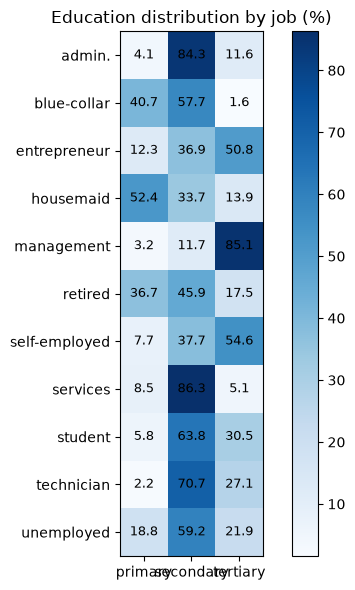

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(edu_by_job.values, cmap='Blues')
ax.set_xticks(range(edu_by_job.shape[1])); ax.set_xticklabels(edu_by_job.columns)
ax.set_yticks(range(edu_by_job.shape[0])); ax.set_yticklabels(edu_by_job.index)
for i in range(edu_by_job.shape[0]):
    for j in range(edu_by_job.shape[1]):
        ax.text(j, i, edu_by_job.values[i, j], ha='center', va='center', fontsize=9)
ax.set_title('Education distribution by job (%)')
plt.colorbar(im)
plt.tight_layout()
plt.show()

In [11]:
from scipy.stats import chi2_contingency

def cramers_v(data, col, target='education'):
    table = pd.crosstab(data[col], data[target])
    chi2, p, dof, _ = chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return chi2, p, v

chi2, p, v = cramers_v(known, 'job')
print(f"직업 vs 학력 → 카이제곱 = {chi2:,.1f}, p-value = {p:.3g}, Cramér's V = {v:.3f}")

직업 vs 학력 → 카이제곱 = 16,040.2, p-value = 0, Cramér's V = 0.557


In [12]:
# 다른 변수와 비교: 학력을 추정하기에 직업이 가장 적합한가?
known['age_group'] = pd.cut(known['age'], bins=[0, 29, 39, 49, 59, 100])

compare = pd.DataFrame({
    col: {"Cramér's V": round(cramers_v(known, col)[2], 3)}
    for col in ['job', 'age_group', 'marital', 'housing', 'contact', 'loan', 'default']
}).T.sort_values("Cramér's V", ascending=False)
compare

,Cramér's V
job,0.557
age_group,0.153
marital,0.127
contact,0.124
housing,0.110
loan,0.061
default,0.011


#### 직업-학력 연관성 판단
- 직업별 학력 분포가 뚜렷하게 구분됨: management는 85.1%가 tertiary, services(86.3%)와 admin.(84.3%)은 대부분 secondary, housemaid는 52.4%가 primary.
- 카이제곱 검정 결과 p < 0.001로 직업과 학력 사이에 통계적으로 유의한 관계가 있으며, Cramér's V = 0.557로 강한 연관성을 보임.
- 다른 변수와 비교하면 연령대(0.153), 결혼 상태(0.127), 연락 방식(0.124) 등보다 3배 이상 높아, 학력을 추정하기에 직업이 가장 적합한 변수임.
- 연령대를 함께 사용해도 대체 정확도가 거의 오르지 않았던 이유도, 연령대와 학력의 연관성이 직업에 비해 약하기 때문으로 설명됨.
- 결론: education의 unknown은 Train 기준 직업별 최빈값으로 대체함.

## 1-6. 데이터 이상치 탐지

In [13]:
import matplotlib.pyplot as plt
num_cols = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

#### IQR로 이상치 후보 탐지
- pdays와 previous는 IQR이 0. (값이 대부분 -1과 0이어서, 이전 연락 기록이 있는 고객 전체가 이상치로 잡힌 것으로 판단됨.) -> 이 두 변수는 IQR로 판단하면 안 된다.

In [14]:
rows = []
for col in num_cols:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = (X_train[col] < lower) | (X_train[col] > upper)

    rows.append({
        '컬럼': col, '하한': lower, '상한': upper,
        '이상치 건수': out.sum(),
        '비율(%)': round(out.mean() * 100, 2),
        '이상치 가입률(%)': round(y_train[out].mean() * 100, 1) if out.any() else None,
        '정상 가입률(%)': round(y_train[~out].mean() * 100, 1)
    })

iqr_table = pd.DataFrame(rows).set_index('컬럼')
display(iqr_table)

,하한,상한,이상치 건수,비율(%),이상치 가입률(%),정상 가입률(%)
컬럼,,,,,,
age,10.5,70.5,287,1.07,44.3,11.3
balance,-1944.5,3443.5,2829,10.50,16.0,11.2
day,-11.5,40.5,0,0.00,NaN,11.7
campaign,-2.0,6.0,1821,6.76,5.1,12.2
pdays,-1.0,-1.0,4939,18.34,22.6,9.3
previous,0.0,0.0,4939,18.34,22.6,9.3


#### 시각화로 분포 확인
시각화 목적:
- 극단값이 몇 개만 동떨어져 있는지, 아니면 꼬리가 길게 이어지는지
- 분포가 한쪽으로 얼마나 치우쳐 있는지
- 이상치가 가입 여부(y)와 관련이 있는지

#### 박스플롯 + 히스토그램

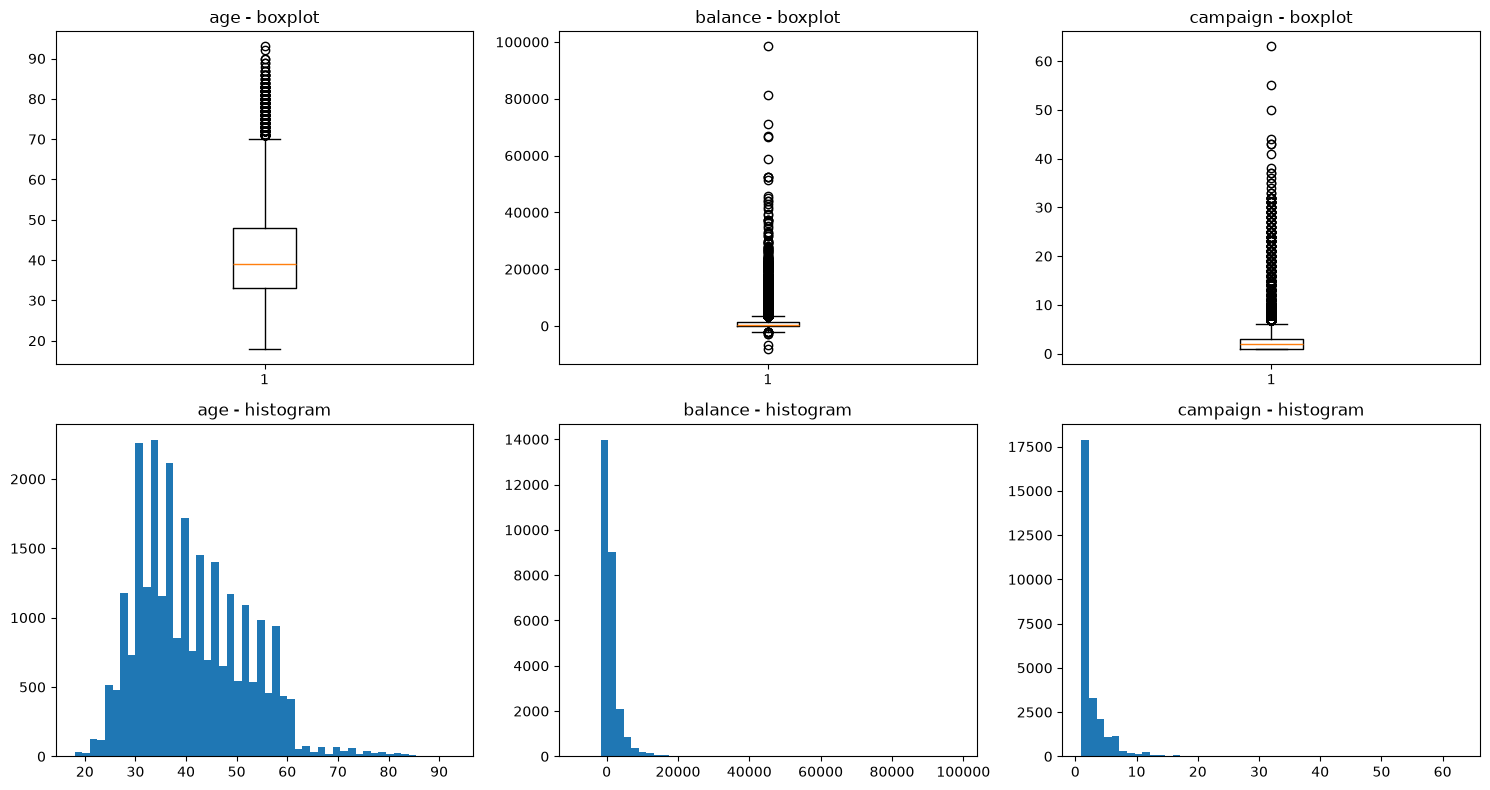

In [15]:
check_cols = ['age', 'balance', 'campaign']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(check_cols):
    axes[0, i].boxplot(X_train[col])
    axes[0, i].set_title(f'{col} - boxplot')

    axes[1, i].hist(X_train[col], bins=50)
    axes[1, i].set_title(f'{col} - histogram')
plt.tight_layout()
plt.show()

#### 박스플롯 + 히스토그램 해석
- age (나이): 
age는 상자가 약 33~48세, 중앙값이 약 39세로 고객 대부분이 25~60세에 분포하며, 60세를 넘으면 고객 수가 급격히 줄어든다. 박스플롯에서 70세를 넘는 값이 이상치로 표시되었으나, 71세부터 93세까지 띄엄띄엄 떨어지지 않고 연속적으로 이어져 있어 입력 오류가 아닌 실제 고령 고객층으로 판단하였다. 따라서 age의 이상치는 별도로 처리하지 않고 유지한다.

- balance (잔고): 
balance는 대부분 고객의 잔고가 0~5,000 근처에 몰려 있고, 소수의 고액 잔고 고객으로 인해 오른쪽으로 꼬리가 매우 긴 분포를 보인다. 이상치는 약 45,000까지 촘촘히 이어지다가 6만~10만 사이에 드문드문 존재하며, 0 아래로도 약 -8,000까지 음수 잔고가 나타난다. 고액 잔고와 음수 잔고(마이너스 통장 등)는 모두 현실적으로 가능한 값이므로 유지하되, 분포의 치우침이 심해 Logistic Regression 적용 시 로그 변환을 검토한다.

- campaign (이번 캠페인 연락 횟수): 
campaign은 고객 대부분이 1~3회 연락을 받았으며, 연락 횟수가 늘수록 고객 수가 빠르게 줄어드는 오른쪽으로 꼬리가 긴 분포를 보인다. 7회부터 약 40회까지 이상치가 연속적으로 이어지고, 50, 55, 63회와 같이 일부 값만 동떨어져 있다. 이는 같은 고객에게 여러 번 연락한 실제 기록으로 볼 수 있고 0회 이하와 같은 규칙 위반도 없으므로 유지하되, Logistic Regression 적용 시 상위 값을 잘라내는 클리핑을 검토한다.

#### 가입 여부별 박스 플롯

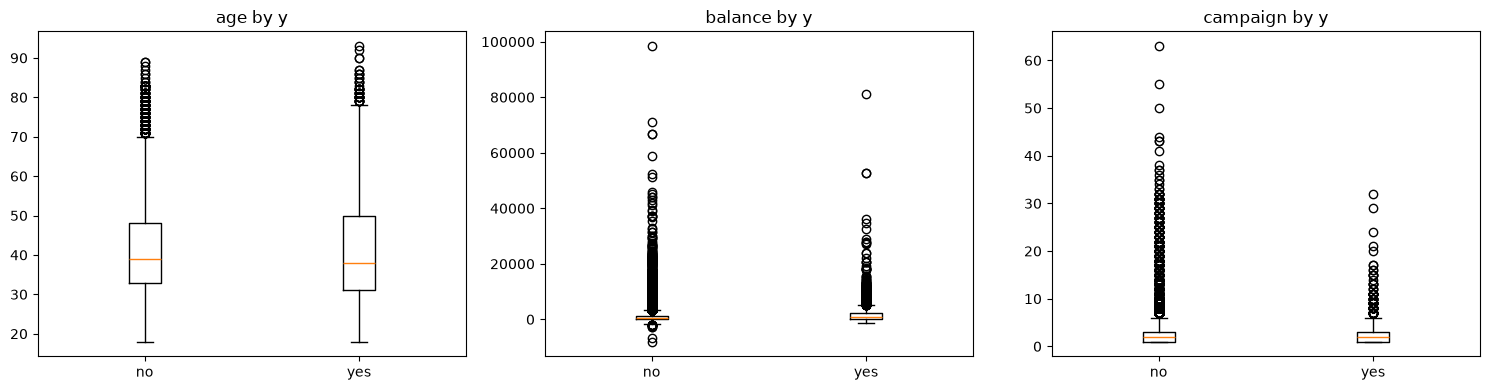

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, check_cols):
    ax.boxplot([X_train.loc[y_train == 0, col], X_train.loc[y_train == 1, col]],
               tick_labels=['no', 'yes'])
    ax.set_title(f'{col} by y')
plt.tight_layout()
plt.show()

#### 가입 여부별 박스플롯 해석
- age (나이): 
가입 고객과 미가입 고객의 중앙값은 각각 약 38세, 39세로 비슷하지만, 가입 고객의 상자(약 31~50세)가 미가입 고객(약 33~48세)보다 위아래로 더 넓게 퍼져 있다. 특히 위쪽 수염이 미가입 고객은 70세에서 끝나는 반면 가입 고객은 약 78세까지 이어져, 가입 고객 중 고령층의 비중이 상대적으로 크다는 것을 알 수 있다. 즉 나이의 평균적인 수준보다는 젊은 층과 고령층처럼 양 끝 연령대에서 가입 경향이 나타나며, 고령 고객의 이상치는 가입 여부를 구분하는 데 유용한 정보로 판단된다.

- balance (잔고): 
두 그룹 모두 상자가 0 근처에 납작하게 눌려 있으나, 가입 고객의 상자가 미가입 고객보다 약간 위쪽으로 넓게 형성되어 있어 가입 고객의 잔고가 전반적으로 조금 더 높은 경향을 보인다. 음수 잔고는 미가입 고객에서 약 -8,000까지 나타나는 반면 가입 고객에서는 0에 가까운 범위에 그친다. 다만 고액 잔고 이상치는 두 그룹 모두에 존재해 특정 그룹에만 나타나는 값이 아니며, 극단값으로 인해 축 범위가 넓어져 차이를 자세히 보기 어려우므로 로그 변환 후 다시 확인할 필요가 있다.

- campaign (이번 캠페인 연락 횟수): 
두 그룹 모두 상자가 1~3회, 중앙값이 약 2회로 일반적인 연락 횟수는 비슷하다. 그러나 미가입 고객은 이상치가 63회까지 이어지는 반면, 가입 고객은 최대 약 32회에 그치고 20회 이상은 드물게 나타난다. 이는 많이 연락한다고 해서 가입으로 이어지지 않으며, 연락 횟수가 매우 많은 고객은 대부분 가입하지 않았음을 보여준다.

#### 꼬리부분 확인(백분위수)


In [17]:
print(X_train[check_cols].describe(percentiles=[0.01, 0.99]).round(1))

           age  balance  campaign
count  26931.0  26931.0   26931.0
mean      40.8   1352.9       2.8
std       10.6   2996.9       3.1
min       18.0  -8019.0       1.0
1%        23.0   -624.7       1.0
99%       71.0  12956.0      16.0
max       93.0  98417.0      63.0


#### 확인 및 판단 내용
- age: 99% 지점이 71세이고 최대는 93세입니다. 70세 이상 고객이 꾸준히 이어져 있어, 동떨어진 오류값이 아니라 고령층 고객군으로 보입니다.
- balance: 오른쪽 꼬리가 매우 깁니다. 99% 지점이 약 13,000인데 최대값은 약 98,000입니다. 
- campaign: 99% 지점이 16회인데 최대 63회까지 있습니다. 40회 이상은 몇 건씩만 드문드문 있습니다.

#### 도메인으로 규칙 판단
- 오류값: 현실에서 불가능한 값(-5세, 32일등) -> 삭제 및 수정
- 극단값: 드물지만 실제로 있을 수 있는 값(93세 등) -> 유지

#### 오류값 규칙 점검

In [18]:
rules = {
    'age':      (X_train['age'] < 18) | (X_train['age'] > 100),   # 성인 고객, 100세 이하
    'day':      (X_train['day'] < 1) | (X_train['day'] > 31),     # 날짜 범위
    'campaign': X_train['campaign'] < 1,                          # 현재 캠페인에서 최소 1회는 연락
    'previous': X_train['previous'] < 0,                          # 횟수는 음수 불가
    'pdays':    (X_train['pdays'] < -1) | (X_train['pdays'] == 0) # -1(연락 없음) 또는 양수만 가능
}

for col, violated in rules.items():
    print(f"{col}: 규칙 위반 {violated.sum()}건")

age: 규칙 위반 0건
day: 규칙 위반 0건
campaign: 규칙 위반 0건
previous: 규칙 위반 0건
pdays: 규칙 위반 0건


#### 극단값 세부 확인

In [19]:
print('음수 잔액 비율:', round((X_train['balance'] < 0).mean() * 100, 2), '%')
print('71세 이상(IQR 상한 70.5세 초과):', (X_train['age'] > 70.5).sum(), '건')
print('잔고 50,000 초과:', (X_train['balance'] > 50000).sum(), '건')
print('campaign 상위 값:', X_train['campaign'].value_counts().sort_index().tail(8).to_dict())

음수 잔액 비율: 8.31 %
71세 이상(IQR 상한 70.5세 초과): 287 건
잔고 50,000 초과: 10 건
campaign 상위 값: {37: 2, 38: 1, 41: 1, 43: 2, 44: 1, 50: 1, 55: 1, 63: 1}


#### previous 오류값 처리
- previous의 최대값 275는 다음으로 큰 값(58)과 약 5배 차이가 나며 혼자 동떨어져 있음.
- 다른 극단값처럼 연속적으로 이어지지 않으므로 입력 오류로 판단함.
- 특정 값(275)을 지우는 대신 'previous가 100을 초과하면 오류값'이라는 규칙을 정해 Train / Val / Test에 동일하게 적용함.
- 계산이 필요 없는 규칙 기반 처리이므로 데이터 누수가 발생하지 않음.

In [20]:
# previous 상위 값 확인 (Train / Val / Test)
for name, data in [('Train', X_train), ('Val', X_val), ('Test', X_test)]:
    print(f"{name} previous 상위 값:", sorted(data['previous'])[-6:])

Train previous 상위 값: [37, 38, 40, 41, 51, 275]
Val previous 상위 값: [25, 26, 29, 30, 55, 58]
Test previous 상위 값: [27, 28, 28, 29, 35, 38]


In [21]:
def drop_previous_error(X_part, y_part, limit=100):
    keep = X_part['previous'] <= limit
    print(f"previous > {limit} 삭제: {(~keep).sum()}건")
    return X_part[keep].copy(), y_part[keep].copy()

X_train, y_train = drop_previous_error(X_train, y_train)
X_val,   y_val   = drop_previous_error(X_val,   y_val)
X_test,  y_test  = drop_previous_error(X_test,  y_test)

for name, data, target in [('Train', X_train, y_train), ('Val', X_val, y_val), ('Test', X_test, y_test)]:
    print(f"{name}: {data.shape}, 가입 비율 {target.mean()*100:.2f}%, previous 최대값 {data['previous'].max()}")

previous > 100 삭제: 1건
previous > 100 삭제: 0건
previous > 100 삭제: 0건
Train: (26930, 15), 가입 비율 11.70%, previous 최대값 51
Val: (8986, 15), 가입 비율 11.70%, previous 최대값 58
Test: (8990, 15), 가입 비율 11.71%, previous 최대값 38


#### pdays 이상치 탐지 (IQR · Z-score · 백분위수)
- pdays는 약 82%가 -1(이전 연락 없음)이라 전체 데이터에 그대로 적용하면 평균·표준편차·사분위수가 왜곡됨.
- 따라서 pdays != -1인 이전 연락 고객만 대상으로 세 가지 방법을 비교함.
  - IQR: Q1 − 1.5×IQR 미만, Q3 + 1.5×IQR 초과
  - Z-score: |z| > 3 (정규분포 가정)
  - 백분위수: 하위 1% 미만, 상위 99% 초과

In [22]:
mask = X_train['pdays'] != -1            # 이전 연락 고객만
p, yp = X_train.loc[mask, 'pdays'], y_train[mask]
print('이전 연락 고객 수:', len(p), '| 왜도(skew):', round(p.skew(), 2))
print(p.describe().round(1))

이전 연락 고객 수: 4938 | 왜도(skew): 0.64
count    4938.0
mean      225.0
std       113.4
min         1.0
25%       138.0
50%       195.0
75%       326.8
max       871.0
Name: pdays, dtype: float64


In [23]:
# 1) IQR
q1, q3 = p.quantile([0.25, 0.75]); iqr = q3 - q1
iqr_lo, iqr_hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out_iqr = (p < iqr_lo) | (p > iqr_hi)

# 2) Z-score
z = (p - p.mean()) / p.std()
out_z = z.abs() > 3
z_hi = p.mean() + 3 * p.std()

# 3) 백분위수 (1% ~ 99%)
pct_lo, pct_hi = p.quantile([0.01, 0.99])
out_pct = (p < pct_lo) | (p > pct_hi)

pdays_table = pd.DataFrame([
    ['IQR',      f'{iqr_lo:.1f} 미만 또는 {iqr_hi:.1f} 초과', out_iqr],
    ['Z-score',  f'|z| > 3 ({z_hi:.1f}일 초과)',             out_z],
    ['백분위수', f'{pct_lo:.1f} 미만 또는 {pct_hi:.1f} 초과', out_pct],
], columns=['방법', '기준', 'out'])
pdays_table['이상치 건수'] = pdays_table['out'].apply(lambda o: o.sum())
pdays_table['비율(%)'] = pdays_table['out'].apply(lambda o: round(o.mean() * 100, 2))
pdays_table['이상치 가입률(%)'] = pdays_table['out'].apply(lambda o: round(yp[o].mean() * 100, 1))
pdays_table['정상 가입률(%)'] = pdays_table['out'].apply(lambda o: round(yp[~o].mean() * 100, 1))
display(pdays_table.drop(columns='out').set_index('방법'))

# 참고: -1을 포함한 전체 데이터에 Z-score를 적용하면
z_all = (X_train['pdays'] - X_train['pdays'].mean()) / X_train['pdays'].std()
print('(참고) -1 포함 전체에 Z-score 적용 시 이상치:', (z_all.abs() > 3).sum(), '건 → 의미 없는 결과')

,기준,이상치 건수,비율(%),이상치 가입률(%),정상 가입률(%)
방법,,,,,
IQR,-145.1 미만 또는 609.9 초과,27,0.55,25.9,22.6
Z-score,|z| > 3 (565.3일 초과),31,0.63,29.0,22.6
백분위수,7.4 미만 또는 521.0 초과,99,2.00,25.3,22.5


(참고) -1 포함 전체에 Z-score 적용 시 이상치: 1022 건 → 의미 없는 결과


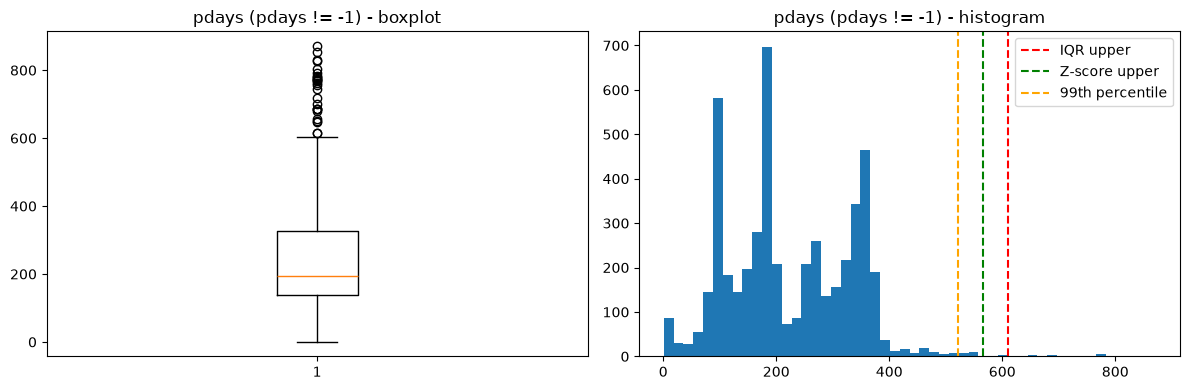

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot(p)
axes[0].set_title('pdays (pdays != -1) - boxplot')
axes[1].hist(p, bins=50)
axes[1].axvline(iqr_hi, color='red', linestyle='--', label='IQR upper')
axes[1].axvline(z_hi, color='green', linestyle='--', label='Z-score upper')
axes[1].axvline(pct_hi, color='orange', linestyle='--', label='99th percentile')
axes[1].set_title('pdays (pdays != -1) - histogram')
axes[1].legend()
plt.tight_layout()
plt.show()

#### pdays 이상치 판단
- 이전 연락 고객(Train 4,938건)을 대상으로 탐지한 결과 IQR 27건(0.55%, 609.9일 초과), Z-score 31건(0.63%, 565.3일 초과), 백분위수 99건(2.00%, 7.4일 미만 또는 521.0일 초과)이 탐지됨.
- IQR과 Z-score는 약 570~610일 이상으로 비슷한 기준을 보여 서로의 결과를 뒷받침함. 분포의 왜도가 0.64로 크게 치우치지 않아 Z-score를 적용해도 무리가 없음.
- 백분위수는 정의상 항상 약 2%를 잘라내므로, 이상치 존재 여부를 판단하기보다 클리핑 기준을 정하는 용도로 활용함.
- 최대값 871일(약 2.4년)은 현실적으로 가능한 값이고, 값이 연속적으로 분포하며, 이상치 구간의 가입률(25~29%)도 정상 구간(약 22.6%)과 큰 차이가 없음.
- 결론: pdays는 삭제하지 않고 유지하며, Logistic Regression 적용 시 IQR 또는 Z-score 상한에서 클리핑을 검토함.
- 참고로 -1을 포함한 전체 데이터에 Z-score를 적용하면 1,022건이 탐지되는데, 이는 이전 연락 이력이 있다는 이유만으로 잡힌 결과이므로 의미가 없음.

#### 이상치 전처리
- IQR(1.5배) 기준으로 Train 데이터(26,931건)를 점검한 결과 age 287건(1.07%), balance 2,829건(10.50%), campaign 1,821건(6.76%)의 이상치가 탐지되었으나, 도메인 규칙상 오류값은 없어 모두 실제로 존재할 수 있는 극단값으로 판단하였다. age는 18~93세로 현실적이며, IQR 상한(70.5세)을 넘는 고객의 가입률이 44.3%로 정상 범위(11.3%)보다 높아 유지하였다. balance의 음수 잔고(8.31%)와 고액 잔고(최대 98,417)도 실제 가능한 값이므로 유지하되, 분포가 크게 치우쳐 있어 Logistic Regression 적용 시 로그 변환을 검토한다. campaign은 IQR 상한(6회)을 넘는 고객의 가입률이 5.1%로 정상 범위(12.2%)보다 낮아 유의미한 정보로 보고 유지하되, Logistic Regression 적용 시 클리핑을 검토한다. day는 이상치가 없었다.
- previous는 최대값 275가 다음으로 큰 값(58)과 크게 동떨어져 있어 입력 오류로 판단하고, 100 초과 값을 오류로 간주하는 규칙을 세 데이터셋에 동일하게 적용하여 삭제하였다(Train 1건, 삭제 후 Train 26,930건).
- pdays는 -1(이전 연락 없음)을 제외한 이전 연락 고객만을 대상으로 IQR, Z-score, 백분위수 세 가지 방법으로 탐지한 결과 각각 27건(0.55%), 31건(0.63%), 99건(2.00%)이 탐지되었다. 그러나 최대값 871일은 현실적으로 가능한 범위이며 값이 연속적으로 분포하고, 이상치 구간의 가입률도 정상 구간과 큰 차이가 없어 삭제하지 않고 유지하였다.

# 2. 베이스라인
- Baseline 정의: 불균형 처리 없음, 기본 하이퍼파라미터, 분류 임계값 0.5
- 모델: Logistic Regression(계수로 영향의 방향 해석), Decision Tree(피처 중요도로 전처리 보완 방향 파악), Dummy(모두 '미가입'으로 예측하는 비교 기준선)
- 평가: Train으로 학습, Validation으로 평가 (Test는 최종 평가 전까지 사용하지 않음)
- 평가 지표: Accuracy, Precision, Recall, F1 (임계값 0.5)을 모두 보고, 여러 조합을 비교할 때는 네 지표의 평균 순위를 사용함. PR-AUC는 참고 지표로 함께 기록함

## 2-1. 공통 설정 및 함수
- 2장부터 7장까지 반복해서 쓰는 라이브러리, 설정값, 함수를 이 셀들에 한 번에 모아 둠. 이후 셀에서는 이 함수들을 불러 쓰기만 함
- `pip install xgboost lightgbm catboost imbalanced-learn` 필요

| 함수 | 역할 |
|---|---|
| make_preprocessor | 인코딩·스케일링 규칙 (Train에서만 fit) |
| OutlierClipper | LR·KNN용 극단값 클리핑 + balance 로그 변환 |
| CatBoostWrapper | CatBoost를 sklearn Pipeline·Stacking에서 쓸 수 있게 감싼 클래스 |
| make_model / make_sampler | 모델, 불균형 처리 도구 생성 |
| build_pipeline | [추가 피처] → [클리핑] → [샘플링] → [전처리] → [모델] 순서로 파이프라인 조립 |
| evaluate | 학습 → Validation 예측 → 지표 계산 |
| run_experiments | 모델 × 처리 방법 실험을 한 번에 실행하고 결과를 저장 |
| add_avg_rank | 네 지표의 평균 순위 계산 |

In [25]:
# ── 라이브러리 ──────────────────────────────────────────────
import os, time, pickle, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, randint, uniform, loguniform

from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import (StratifiedKFold, cross_val_score, cross_val_predict,
                                     RandomizedSearchCV)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix, precision_recall_curve,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              AdaBoostClassifier, StackingClassifier)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from imblearn.pipeline import Pipeline as ImbPipeline       # 샘플링을 파이프라인에 넣기 위해 imblearn 사용
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTENC

# ── 설정값 ──────────────────────────────────────────────────
RANDOM_STATE = 42
NUM_COLS = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
NOM_COLS = ['job', 'marital', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
EDU_COL = ['education']
EDU_ORDER = [['primary', 'secondary', 'tertiary']]
CAT_COLS = NOM_COLS + EDU_COL                              # 범주형 전체 (SMOTENC, CatBoost용)
RANK_METRICS = ['Accuracy', 'Precision', 'Recall', 'F1']  # 평균 순위에 쓰는 네 지표

SCALE_MODELS = {'Logistic Regression', 'KNN'}              # 스케일링·클리핑이 필요한 모델
NO_CW_MODELS = {'KNN', 'Dummy'}                            # Class Weight 개념이 없는 모델
SAMPLE_WEIGHT_MODELS = {'Gradient Boosting', 'AdaBoost'}   # Class Weight를 sample_weight로 넣는 모델
SCALE_POS = (y_train == 0).sum() / (y_train == 1).sum()   # XGBoost용 가입 가중치 (약 7.5)

CATBOOST_ITERATIONS = 1000   # 느리거나 커널이 죽으면 500으로 줄이기
CATBOOST_THREADS = 4
CACHE_FILE = 'experiment_cache.pkl'   # 실험 결과 저장 파일 (지우면 처음부터 다시 실행)

In [26]:
# ── 전처리 도구 ─────────────────────────────────────────────
def make_preprocessor(scale, extra_num=(), extra_cat=()):
    """수치형(스케일링 선택) + 학력(순서형) + 범주형(원-핫). Train에서만 fit됨"""
    return ColumnTransformer([
        ('num', StandardScaler() if scale else 'passthrough', NUM_COLS + list(extra_num)),
        ('edu', OrdinalEncoder(categories=EDU_ORDER), EDU_COL),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), NOM_COLS + list(extra_cat))])


class OutlierClipper(BaseEstimator, TransformerMixin):
    """LR·KNN용: balance·campaign·pdays 상위 1% 클리핑 + balance 부호 유지 로그 변환"""
    def __init__(self, cols=('balance', 'campaign', 'pdays'), q=0.99, log_balance=True):
        self.cols, self.q, self.log_balance = cols, q, log_balance

    def fit(self, X, y=None):                          # 기준은 Train에서만 계산
        self.upper_ = {}
        for c in self.cols:
            s = X.loc[X['pdays'] != -1, 'pdays'] if c == 'pdays' else X[c]   # pdays는 -1 제외
            self.upper_[c] = s.quantile(self.q)
        return self

    def transform(self, X):
        X = X.copy()
        for c, u in self.upper_.items():
            X[c] = X[c].clip(upper=u)
        if self.log_balance:
            X['balance'] = np.sign(X['balance']) * np.log1p(X['balance'].abs())
        return X


class CatBoostWrapper(ClassifierMixin, BaseEstimator):
    """CatBoost를 sklearn의 Pipeline·Stacking·튜닝에서 쓸 수 있게 감싼 클래스"""
    def __init__(self, cat_features=tuple(CAT_COLS), auto_class_weights=None,
                 iterations=CATBOOST_ITERATIONS, learning_rate=None, depth=6, l2_leaf_reg=3,
                 thread_count=CATBOOST_THREADS, random_seed=RANDOM_STATE):
        self.cat_features = cat_features
        self.auto_class_weights = auto_class_weights
        self.iterations, self.learning_rate = iterations, learning_rate
        self.depth, self.l2_leaf_reg = depth, l2_leaf_reg
        self.thread_count, self.random_seed = thread_count, random_seed

    def fit(self, X, y):
        self.model_ = CatBoostClassifier(
            cat_features=list(self.cat_features), auto_class_weights=self.auto_class_weights,
            iterations=self.iterations, learning_rate=self.learning_rate, depth=self.depth,
            l2_leaf_reg=self.l2_leaf_reg, thread_count=self.thread_count, random_seed=self.random_seed,
            verbose=0, allow_writing_files=False, used_ram_limit='4gb')
        self.model_.fit(X, y)
        self.classes_ = self.model_.classes_
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

    def predict(self, X):
        return self.model_.predict(X)

In [27]:
# ── 모델·샘플러·파이프라인 ──────────────────────────────────
def make_model(name, use_cw=False, extra_cat=()):
    """모델 이름으로 모델 생성. use_cw=True면 Class Weight 적용"""
    cw = 'balanced' if use_cw else None
    builders = {
        'Dummy':               lambda: DummyClassifier(strategy='most_frequent'),
        'Logistic Regression': lambda: LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight=cw),
        'KNN':                 lambda: KNeighborsClassifier(n_neighbors=5),
        'Decision Tree':       lambda: DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight=cw),
        'Random Forest':       lambda: RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, class_weight=cw),
        'Gradient Boosting':   lambda: GradientBoostingClassifier(random_state=RANDOM_STATE),
        'AdaBoost':            lambda: AdaBoostClassifier(random_state=RANDOM_STATE),
        'XGBoost':             lambda: XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1,
                                                     scale_pos_weight=SCALE_POS if use_cw else 1),
        'LightGBM':            lambda: LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, class_weight=cw),
        'CatBoost':            lambda: CatBoostWrapper(cat_features=tuple(CAT_COLS + list(extra_cat)),
                                                       auto_class_weights='Balanced' if use_cw else None),
    }
    return builders[name]()


RATIOS = {'1:3': 1/3, '1:2': 1/2, '1:1': 1.0}   # 가입 : 미가입 (sampling_strategy = 가입 수 ÷ 미가입 수)

def make_sampler(method, extra_cat=()):
    """'RUS 1:3', 'SMOTE 1:2' 같은 이름으로 샘플러 생성. 그 외('처리 없음', 'Class Weight')는 None"""
    if method.startswith('RUS'):
        return RandomUnderSampler(sampling_strategy=RATIOS[method.split()[1]], random_state=RANDOM_STATE)
    if method.startswith('SMOTE'):   # 범주형을 고려하는 SMOTENC (원-핫 칼럼에 0.4 같은 값이 생기지 않음)
        return SMOTENC(categorical_features=CAT_COLS + list(extra_cat),
                       sampling_strategy=RATIOS[method.split()[1]], random_state=RANDOM_STATE)
    return None


def build_pipeline(name, method='처리 없음', clip=False, extra_num=(), extra_cat=(), pre_steps=()):
    """[추가 피처] → [클리핑(LR·KNN, clip=True일 때)] → [샘플링] → [전처리] → [모델]"""
    steps = list(pre_steps)
    if clip and name in SCALE_MODELS:
        steps.append(('clip', OutlierClipper()))
    sampler = make_sampler(method, extra_cat)
    if sampler is not None:
        steps.append(('sampler', sampler))
    if name != 'CatBoost':                             # CatBoost는 범주형을 직접 처리하므로 인코딩 없음
        steps.append(('prep', make_preprocessor(name in SCALE_MODELS, extra_num, extra_cat)))
    steps.append(('model', make_model(name, method == 'Class Weight', extra_cat)))
    return ImbPipeline(steps)


def fit_params_for(name, method, y_tr):
    """Gradient Boosting·AdaBoost의 Class Weight는 행별 가중치(sample_weight)로 전달"""
    if method == 'Class Weight' and name in SAMPLE_WEIGHT_MODELS:
        return {'model__sample_weight': compute_sample_weight('balanced', y_tr)}
    return {}

In [28]:
# ── 평가·실험 실행 ──────────────────────────────────────────
def evaluate(name, pipe, X_tr=None, X_ev=None, fit_params=None, threshold=0.5):
    """학습 → Validation 예측 → 지표 계산. 반환: (결과 dict, 가입 확률)"""
    X_tr = X_train if X_tr is None else X_tr
    X_ev = X_val if X_ev is None else X_ev
    start = time.time()
    pipe.fit(X_tr, y_train, **(fit_params or {}))
    train_time = time.time() - start
    proba = pipe.predict_proba(X_ev)[:, 1]
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    return {'모델': name,
            'Accuracy':  round(accuracy_score(y_val, pred), 4),
            'Precision': round(precision_score(y_val, pred, zero_division=0), 4),
            'Recall':    round(recall_score(y_val, pred, zero_division=0), 4),
            'F1':        round(f1_score(y_val, pred, zero_division=0), 4),
            'PR-AUC':    round(average_precision_score(y_val, proba), 4),
            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            '학습 시간(초)': round(train_time, 2)}, proba


CACHE = pickle.load(open(CACHE_FILE, 'rb')) if os.path.exists(CACHE_FILE) else {}

def cached(key, job):
    """결과가 저장되어 있으면 불러오고, 없으면 실행 후 저장 (커널이 죽어도 이어서 실행 가능)"""
    if key not in CACHE:
        CACHE[key] = job()
        pickle.dump(CACHE, open(CACHE_FILE, 'wb'))
        gc.collect()
    return CACHE[key]


def run_experiments(model_names, methods, tag, X_tr=None, X_ev=None, **build_kw):
    """모델 × 처리 방법 실험. 반환: (결과표, {(모델, 방법): 확률})"""
    rows, probas = [], {}
    for name in model_names:
        start = time.time()
        for method in methods:
            if method == 'Class Weight' and name in NO_CW_MODELS:
                continue
            def job():
                pipe = build_pipeline(name, method, **build_kw)
                return evaluate(f'{name} | {method}', pipe, X_tr, X_ev, fit_params_for(name, method, y_train))
            res, proba = cached((tag, name, method), job)
            rows.append({**res, '모델명': name, '처리 방법': method})
            probas[(name, method)] = proba
        print(f'{name:20s} 완료 ({time.time() - start:.0f}초)')
    return pd.DataFrame(rows), probas


def add_avg_rank(df, metrics=RANK_METRICS):
    """네 지표를 각각 높은 순으로 순위 매긴 뒤 평균 (작을수록 골고루 좋음)"""
    df = df.copy()
    df['평균 순위'] = df[metrics].rank(ascending=False).mean(axis=1).round(2)
    return df

In [29]:
# ── 그래프 ─────────────────────────────────────────────────
def plot_confusions(probas, keys, titles, threshold=0.5):
    """여러 모델의 Confusion Matrix를 나란히 그림"""
    fig, axes = plt.subplots(1, len(keys), figsize=(5 * len(keys), 4))
    for ax, key, title in zip(np.atleast_1d(axes), keys, titles):
        pred = (probas[key] >= threshold).astype(int)
        ConfusionMatrixDisplay(confusion_matrix(y_val, pred), display_labels=['no', 'yes']).plot(
            ax=ax, colorbar=False, values_format='d')
        ax.set_title(title)
    plt.tight_layout()
    plt.show()


def plot_heatmap(df, metric, ax, rows, cols, col_labels=None, cmap='YlGnBu'):
    """모델(행) × 처리 방법(열) 표를 색깔 칸으로 그림"""
    pv = df.pivot(index='모델명', columns='처리 방법', values=metric).reindex(index=rows, columns=cols)
    im = ax.imshow(pv.values, cmap=cmap, aspect='auto')
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(col_labels or cols, rotation=30)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels(rows)
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            v = pv.values[i, j]
            ax.text(j, i, '-' if np.isnan(v) else f'{v:.3f}', ha='center', va='center', fontsize=8)
    ax.set_title(f'{metric} (Validation)')
    return pv

## 2-2. 모델 학습 및 Validation 평가

In [30]:
baseline_pipes = {name: build_pipeline(name) for name in ['Dummy', 'Logistic Regression', 'Decision Tree']}

rows, base_probas = [], {}
for name, pipe in baseline_pipes.items():
    res, base_probas[name] = evaluate(name, pipe)
    rows.append(res)

baseline_df = pd.DataFrame(rows).set_index('모델')
print('Validation 가입 비율:', round(y_val.mean(), 4))
baseline_df[RANK_METRICS + ['PR-AUC', 'TP', 'FP', 'FN', 'TN']]

Validation 가입 비율: 0.117


,Accuracy,Precision,Recall,F1,PR-AUC,TP,FP,FN,TN
모델,,,,,,,,,
Dummy,0.8830,0.0000,0.0000,0.0000,0.1170,0,0,1051,7935
Logistic Regression,0.8922,0.6385,0.1798,0.2806,0.4034,189,107,862,7828
Decision Tree,0.8310,0.3000,0.3340,0.3161,0.1781,351,819,700,7116


#### 베이스라인 결과 해석
- Accuracy는 의미가 없음: Dummy가 가입 고객을 한 명도 찾지 못하는데도(Recall 0) Accuracy 88.3%이며, LR은 89.2%로 Dummy와 1%p 차이에 불과하고 Decision Tree는 83.1%로 오히려 Dummy보다 낮음.
- PR-AUC: LR 0.403으로 기준선(0.117) 대비 약 3.4배이지만, Decision Tree는 0.178로 기준선보다 조금 나은 수준에 그침.
- ROC-AUC는 실제보다 좋아 보임: LR 0.764로 높아 보이지만 다수 클래스(미가입)를 잘 맞히는 것에도 점수를 주기 때문이며, 불균형 데이터에서는 PR-AUC가 더 정직함.
- LR은 '가입' 예측을 매우 조심스럽게 함: Precision 63.9%로 '가입'이라고 예측하면 꽤 맞지만 Recall이 18.0%에 그쳐, 실제 가입 고객 1,051명 중 862명을 놓침. 다수 클래스에 끌린 불균형 데이터의 전형적인 모습임.
- Decision Tree는 반대로 과감함: Recall 33.4%로 가입 고객을 더 많이 찾았지만 Precision이 30.0%로 떨어지고, 괜히 '가입'으로 예측한 고객(FP)이 819명으로 LR(107명)의 약 7.7배임.

## 2-3. 과적합 확인 (Train vs Validation)

In [31]:
fit_check = pd.DataFrame({
    name: {'Train F1': round(f1_score(y_train, baseline_pipes[name].predict(X_train)), 4),
           'Val F1':   baseline_df.loc[name, 'F1']}
    for name in ['Logistic Regression', 'Decision Tree']}).T
display(fit_check)

dt = baseline_pipes['Decision Tree'].named_steps['model']
print('Decision Tree 깊이:', dt.get_depth(), '| 잎 수:', dt.get_n_leaves())
print('Decision Tree 확률 값의 종류:', np.unique(base_probas['Decision Tree']))

,Train F1,Val F1
Logistic Regression,0.2781,0.2806
Decision Tree,1.0000,0.3161


Decision Tree 깊이: 40 | 잎 수: 3533
Decision Tree 확률 값의 종류: [0. 1.]


#### 과적합 해석
- Logistic Regression: Train F1 0.278, Val F1 0.281로 거의 같아 과적합이 없음.
- Decision Tree: Train F1 1.0, Val F1 0.316으로 Train을 외운 심한 과적합 상태. 깊이 제한이 없어 깊이 40, 잎 3,533개까지 자랐고, 잎마다 고객이 거의 한 명씩 남아 확률이 0 또는 1로만 나옴.
- 확률이 0·1뿐이라 임계값을 조정할 여지가 없고 PR-AUC도 낮음. 이 과적합은 2-6의 Decision Tree 기본 피처 중요도 해석에도 영향을 줌.

## 2-4. Confusion Matrix

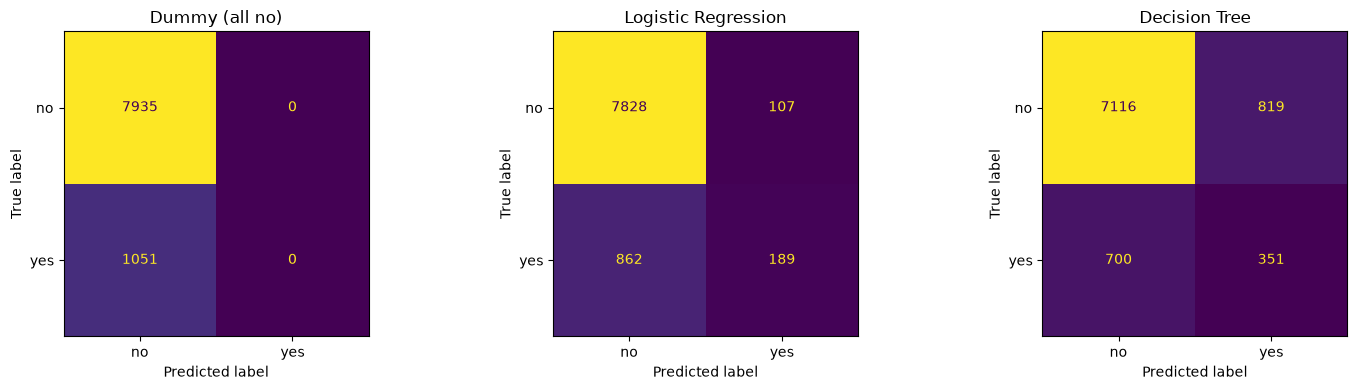

In [32]:
plot_confusions(base_probas, ['Dummy', 'Logistic Regression', 'Decision Tree'],
                ['Dummy (all no)', 'Logistic Regression', 'Decision Tree'])

#### Confusion Matrix 해석
| 모델 | TP (찾은 가입 고객) | FP (괜히 전화할 고객) | FN (놓친 가입 고객) | TN |
|---|---|---|---|---|
| Dummy | 0 | 0 | 1,051 | 7,935 |
| Logistic Regression | 189 | 107 | 862 | 7,828 |
| Decision Tree | 351 | 819 | 700 | 7,116 |

- 두 모델 모두 FN이 TP보다 많음. LR은 찾아낸 가입 고객보다 놓친 고객이 약 4.6배, Decision Tree는 약 2배.
- Decision Tree는 LR보다 가입 고객을 162명 더 찾았지만(TP 189 → 351), 괜히 전화할 고객은 712명 늘었음(FP 107 → 819). 가입 고객을 더 찾으려 하면 오판도 늘어나는 Precision–Recall Trade-off가 나타나며, Decision Tree는 과적합으로 그 대가가 특히 큼.
- 마케팅 관점에서 FN은 '놓친 매출', FP는 '헛걸음한 통화 비용'이며, 어느 쪽을 더 줄일지는 비즈니스 비용 분석 단계에서 결정함.

## 2-5. Precision-Recall 곡선
- 임계값을 1에서 0으로 낮춰 가며 그린 곡선. 오른쪽 위에 가까울수록 좋은 모델
- 표는 Logistic Regression 곡선 위의 주요 지점 (같은 Recall에서의 Precision과 그때의 임계값)

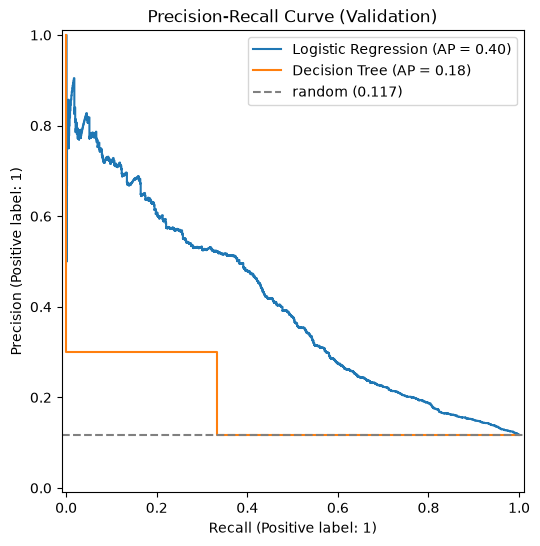

LR이 가입 확률 0.5 이상을 준 고객 비율: 0.033


,목표 Recall,Precision,임계값
0,0.3,0.53,0.31
1,0.5,0.38,0.16
2,0.7,0.22,0.10


In [33]:
fig, ax = plt.subplots(figsize=(8, 6))
for name in ['Logistic Regression', 'Decision Tree']:
    PrecisionRecallDisplay.from_predictions(y_val, base_probas[name], name=name, ax=ax)
ax.axhline(y_val.mean(), color='gray', linestyle='--', label=f'random ({y_val.mean():.3f})')
ax.set_title('Precision-Recall Curve (Validation)')
ax.legend(loc='upper right')
plt.show()

p, r, t = precision_recall_curve(y_val, base_probas['Logistic Regression'])
points = []
for target in [0.3, 0.5, 0.7]:
    i = np.where(r >= target)[0][-1]
    points.append([target, round(p[i], 2), round(t[min(i, len(t) - 1)], 2)])
print('LR이 가입 확률 0.5 이상을 준 고객 비율:', round((base_probas['Logistic Regression'] >= 0.5).mean(), 3))
pd.DataFrame(points, columns=['목표 Recall', 'Precision', '임계값'])

#### PR 곡선 해석
- Logistic Regression은 매끄러운 곡선을 그림. 확률이 촘촘해서 임계값을 조정하며 Recall과 Precision 사이에서 원하는 지점을 고를 수 있음.
- 임계값 0.5는 이 데이터에 너무 높음: LR이 가입 확률 0.5 이상을 준 고객은 3.3%에 불과해 Recall이 낮게 나옴. 임계값을 0.16으로 낮추면 Recall 50%에서 Precision 38%를 얻을 수 있음.
- 다만 Recall 70%를 얻으려면 Precision이 22%까지 떨어져, 약 4~5명에게 전화해야 1명이 가입하는 수준이 됨. 어느 지점을 고를지가 이후 단계의 핵심 결정임.
- Decision Tree는 곡선이 아니라 꺾인 선 하나로 나타남. 확률이 0과 1뿐이라 가능한 지점이 (Recall 33.4%, Precision 30.0%) 하나밖에 없고, 임계값을 바꿔도 결과가 달라지지 않음. 기본 설정의 Decision Tree는 임계값 조정으로 개선할 수 없는 구조임.

## 2-6. 피처 중요도 (Decision Tree 기본 중요도 vs Permutation Importance)
- 기본 중요도: Train에서 트리를 나눌 때 얼마나 자주 쓰였는지 (연속형 변수를 과대평가하는 경향)
- Permutation Importance: Validation에서 변수 하나를 섞었을 때 PR-AUC가 얼마나 떨어지는지 (실제 예측 기여도)

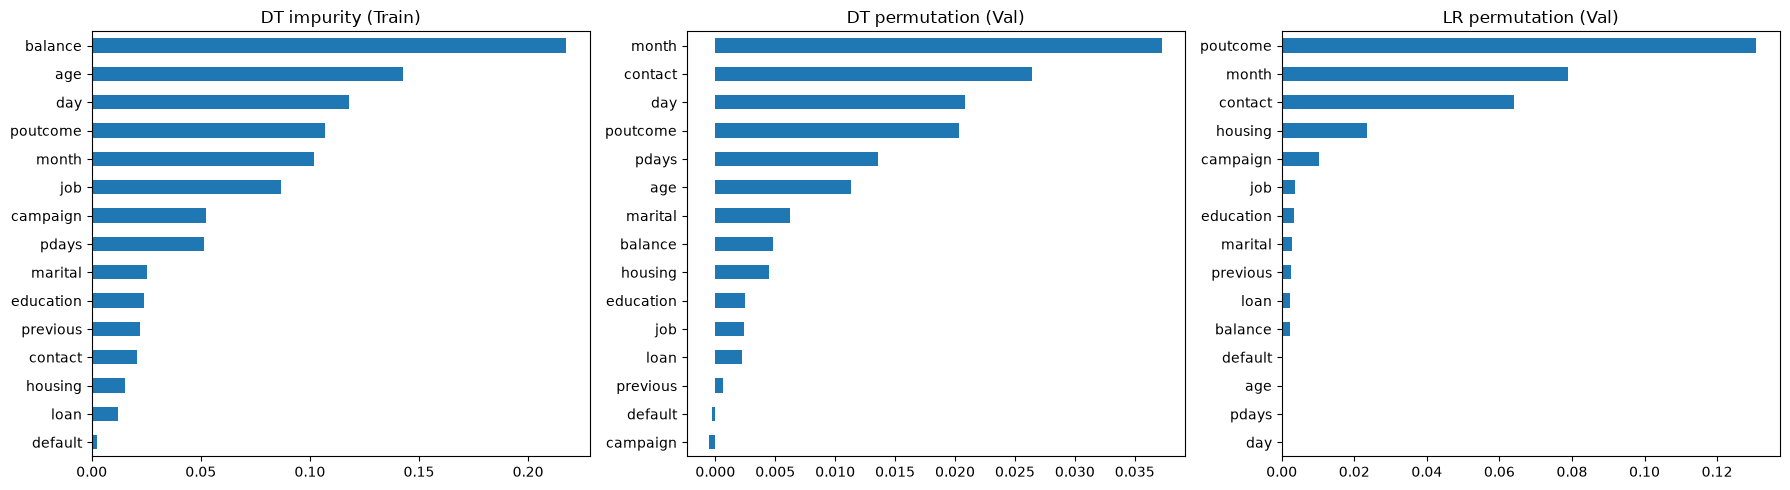

,DT 기본 중요도(Train),DT Permutation(Val),LR Permutation(Val)
month,0.1019,0.0373,0.0789
contact,0.0209,0.0264,0.0640
day,0.1180,0.0208,0.0002
poutcome,0.1069,0.0203,0.1308
pdays,0.0515,0.0136,0.0002
age,0.1428,0.0113,0.0004
marital,0.0253,0.0062,0.0029
balance,0.2175,0.0048,0.0022
housing,0.0153,0.0045,0.0235
education,0.0240,0.0025,0.0034


In [34]:
def original_name(col):
    """원-핫으로 쪼개진 칼럼 이름을 원래 변수 이름으로"""
    return next(c for c in NUM_COLS + EDU_COL + NOM_COLS if col == c or col.startswith(c + '_'))

def perm_importance(pipe):
    pi = permutation_importance(pipe, X_val, y_val, scoring='average_precision',
                                n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    return pd.Series(pi.importances_mean, index=X_val.columns)

dt_pipe, lr_pipe = baseline_pipes['Decision Tree'], baseline_pipes['Logistic Regression']
feat_names = [n.split('__', 1)[1] for n in dt_pipe.named_steps['prep'].get_feature_names_out()]
mdi = pd.Series(dt_pipe.named_steps['model'].feature_importances_,
                index=[original_name(n) for n in feat_names]).groupby(level=0).sum()

importance_df = pd.DataFrame({'DT 기본 중요도(Train)': mdi,
                              'DT Permutation(Val)': perm_importance(dt_pipe),
                              'LR Permutation(Val)': perm_importance(lr_pipe)}
                             ).round(4).sort_values('DT Permutation(Val)', ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, title in zip(axes, importance_df.columns, ['DT impurity (Train)', 'DT permutation (Val)', 'LR permutation (Val)']):
    importance_df[col].sort_values().plot(kind='barh', ax=ax, title=title)
plt.tight_layout()
plt.show()
importance_df

#### 피처 중요도 해석
- 두 방식의 순위가 크게 다름: Decision Tree 기본 중요도 1위인 balance(0.218)는 Permutation에서 0.005로 거의 영향이 없음. age(0.143), day(0.118)도 기본 중요도는 높지만 Permutation은 낮음. 값이 다양해서 과적합된 트리가 Train 고객을 구분하는 데 자주 썼을 뿐, 실제 예측에는 도움이 크지 않은 것으로 판단됨.
- 실제로 중요한 변수는 month, contact, poutcome: Decision Tree Permutation 상위는 month(0.037), contact(0.026), day(0.021), poutcome(0.020) 순이고, LR Permutation 상위는 poutcome(0.131), month(0.079), contact(0.064) 순. 서로 다른 방식의 두 모델에서 month, contact, poutcome이 공통으로 상위에 있어 신뢰할 수 있음.
- day는 Decision Tree에서만 3위이고 LR에서는 거의 0임. 날짜(1~31일)와 가입 여부가 직선적인 관계가 아니어서 LR은 활용하지 못하고, 트리는 특정 날짜 구간으로 나눠 활용한 것으로 보임. 다만 과적합된 트리의 결과라 추가 확인이 필요함.
- 기여도가 매우 작은 변수: education(0.003), job(0.002), balance(0.005), campaign(−0.001). education 대체나 balance 이상치 처리를 더 세밀하게 다듬어도 성능 차이는 작을 것으로 예상됨.
- Decision Tree는 과적합 상태라 Permutation 값 자체가 LR보다 작고 불안정할 수 있으므로, 두 모델에서 공통으로 나타난 변수를 중심으로 해석함. 보고서에는 Permutation Importance를 기준으로 사용함.

## 2-7. Logistic Regression 계수 (영향의 방향)
- 양수: 가입 가능성을 높이는 쪽 / 음수: 가입 가능성을 낮추는 쪽

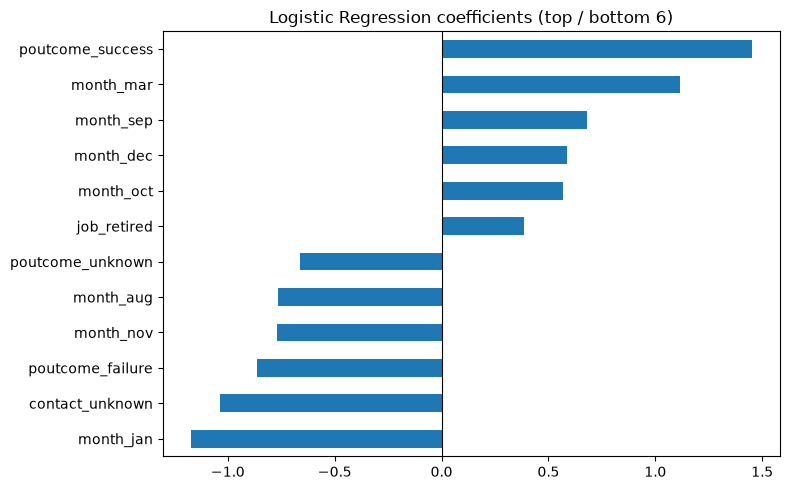

month_jan          -1.173
contact_unknown    -1.038
poutcome_failure   -0.864
month_nov          -0.770
month_aug          -0.763
poutcome_unknown   -0.663
job_retired         0.385
month_oct           0.570
month_dec           0.585
month_sep           0.679
month_mar           1.114
poutcome_success    1.452
dtype: float64

In [35]:
lr_names = [n.split('__', 1)[1] for n in lr_pipe.named_steps['prep'].get_feature_names_out()]
coef = pd.Series(lr_pipe.named_steps['model'].coef_[0], index=lr_names).sort_values()
top_coef = pd.concat([coef.head(6), coef.tail(6)]).round(3)

top_coef.plot(kind='barh', figsize=(8, 5), title='Logistic Regression coefficients (top / bottom 6)')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()
top_coef

#### LR 계수 해석
- 가입 가능성을 높이는 쪽: poutcome_success(+1.45)가 가장 강하고, month_mar(+1.11), sep(+0.68), dec(+0.59), oct(+0.57) 순. 이전 캠페인에서 가입한 고객과 3·9·10·12월 연락이 가입과 관련이 큼.
- 가입 가능성을 낮추는 쪽: month_jan(−1.17), contact_unknown(−1.04), poutcome_failure(−0.86), month_nov(−0.77), aug(−0.76), poutcome_unknown(−0.66).
- Permutation 결과와 마찬가지로 month, poutcome, contact 관련 항목이 계수 상·하위를 차지함.

## 2-8. 피처 중요도 확인 시점 검증
- 불균형 처리(Class Weight)를 해도 중요한 변수가 같은지 확인. 같다면 지금 결과로 전처리를 확정해도 됨

In [36]:
perm_cmp = {}
for name in ['Logistic Regression', 'Decision Tree']:
    for method in ['처리 없음', 'Class Weight']:
        pipe = build_pipeline(name, method).fit(X_train, y_train)
        perm_cmp[f'{name} | {method}'] = perm_importance(pipe)

print('Permutation Importance 순위 (Decision Tree 처리 없음 기준 상위 6개)')
pd.DataFrame(perm_cmp).rank(ascending=False).astype(int).sort_values('Decision Tree | 처리 없음').head(6)

Permutation Importance 순위 (Decision Tree 처리 없음 기준 상위 6개)


,Logistic Regression | 처리 없음,Logistic Regression | Class Weight,Decision Tree | 처리 없음,Decision Tree | Class Weight
month,2,2,1,1
contact,3,3,2,3
day,14,13,3,5
poutcome,1,1,4,4
pdays,15,14,5,2
age,12,15,6,8


#### 확인 시점 해석
- Logistic Regression은 Class Weight 적용 전후에 상위 3개(poutcome, month, contact)의 순위가 완전히 동일함.
- Decision Tree는 month가 적용 전후 모두 1위이고, contact·poutcome도 상위 4위 안에 유지됨. 다만 pdays가 5위에서 2위로 올라가는 등 LR보다 순위 변동이 있는데, 이는 과적합된 단일 트리라 결과가 불안정하기 때문으로 보임.
- 피처 중요도는 '데이터 안에서 가입 여부를 알려주는 신호가 어디 있는가'를 보여주며, 불균형 처리는 모델의 판단 기준(과감함)을 바꿀 뿐 핵심 신호의 위치는 크게 바꾸지 않음.
- 결론: 핵심 변수(month, poutcome, contact)는 불균형 처리 전후에 유지되므로, 지금(Baseline) 결과로 전처리를 확정한 뒤 불균형 처리 실험을 진행함. 불균형 실험 후에 전처리를 바꾸면 모든 실험을 다시 해야 하므로 전처리는 먼저 확정하는 것이 효율적임. 최종 모델의 피처 중요도는 모델 선정 후 설명 목적으로 다시 확인함.

## 2-9. 베이스라인 종합 및 다음 단계
#### 종합
- 불균형 처리를 하지 않은 Baseline에서 Logistic Regression은 PR-AUC 0.403으로 기준선(0.117) 대비 약 3.4배의 성능을 보였으나, 임계값 0.5에서는 Recall이 18.0%에 그쳐 실제 가입 고객의 82%를 놓쳤음.
- Decision Tree는 기본 설정에서 깊이 40까지 자라 Train PR-AUC 1.0의 심한 과적합을 보였고, 확률을 0과 1로만 출력해 PR-AUC가 0.178에 그쳤음. Recall(33.4%)은 LR보다 높지만 FP가 819건으로 Precision이 30.0%까지 떨어졌음.
- Accuracy는 Dummy(88.3%)와 거의 같거나 더 낮아 평가 지표로 의미가 없으며, Precision·Recall·F1을 함께 보는 평가가 필요함이 확인됨.
- 피처 중요도는 Decision Tree 기본 중요도가 연속형 변수를 과대평가하여 Permutation Importance로 보완하였고, 두 모델 모두 month, poutcome, contact가 가장 중요한 변수였으며 balance·job·education의 기여도는 매우 작았음.

#### 전처리 재점검 항목 (중요 변수 기준)
1. contact unknown과 month의 관계: contact unknown이 5·6월에 집중되어 있어, contact_unknown의 강한 음의 계수(−1.04)가 '연락 방식 미상' 자체의 정보인지, 가입률이 낮은 5·6월이라는 정보를 중복으로 담고 있는지 확인 필요.
2. month와 수집 시기의 관계: 데이터가 2008~2010년에 걸쳐 있고 시기별 가입률 차이가 커서, month가 계절 효과가 아닌 '수집 시기'를 대신 나타내는지 확인 필요 (무작위 분할 시 성능이 실제보다 높게 보일 가능성).
3. poutcome·pdays·previous의 중복 정보: 세 변수 모두 '이전 연락 없음'을 담고 있어, 이전 연락 여부 플래그 생성이나 poutcome의 other 범주 처리 검토.
4. day의 활용: Decision Tree에서만 중요하게 나타나, 특정 날짜 구간의 효과인지 과적합의 결과인지 확인 필요.
5. 추가 처리가 필요 없는 부분: education, job, balance는 예측 기여도가 작아 현재 전처리 수준으로 마무리함.

#### 다음 단계
- 위 재점검 결과로 전처리를 확정한 뒤, 불균형 처리(Class Weight → Random Under Sampling → SMOTE, 비율 1:3 / 1:2 / 1:1) 실험과 다른 모델(Random Forest, KNN, Gradient Boosting, XGBoost, LightGBM, AdaBoost, Stacking) 비교를 진행함.
- Decision Tree는 max_depth, min_samples_leaf 등으로 과적합을 줄인 버전과 함께 비교함.

# 3. 불균형 처리
- 목적: 클래스 불균형(가입 11.7% : 미가입 88.3%, 약 1 : 7.5)을 처리했을 때 성능이 어떻게 달라지는지, 개선 효과와 부작용을 함께 확인함
- 대상 모델: 베이스라인과 같은 Logistic Regression, Decision Tree
- 처리 방법 8가지: 처리 없음, Class Weight, Random Under Sampling(1:3, 1:2, 1:1), SMOTE(1:3, 1:2, 1:1)
- 이 장에서 비율(1:3, 1:2, 1:1)별 변화를 확인한 뒤, 4장부터는 결과가 좋은 중간 단계 하나만 남겨 비교 대상을 줄임
- 누수 방지: 샘플링은 파이프라인 안에서 Train에만 적용되고, Validation은 실제 분포(가입 11.7%)를 유지함

## 3-1. 불균형 처리 방법 정의
- RUS(Random Under Sampling): 미가입 고객을 무작위로 줄임. 학습이 빠르지만 정보를 버림
- SMOTE: 가입 고객 사이에 가짜 가입 고객을 만들어 늘림. 범주형 변수를 고려하는 SMOTENC 사용
- Class Weight: 데이터는 그대로 두고, 가입 고객을 틀렸을 때 벌점을 더 크게 줌

In [37]:
METHODS_ALL = ['처리 없음', 'Class Weight', 'RUS 1:3', 'RUS 1:2', 'RUS 1:1', 'SMOTE 1:3', 'SMOTE 1:2', 'SMOTE 1:1']
METHODS_EN = {'처리 없음': 'None', 'Class Weight': 'CW'}   # 그래프용 영문 표기

# (확인용) 샘플링 후 Train 크기
size_rows = [['처리 없음 / Class Weight', len(y_train), int(y_train.sum()), int((y_train == 0).sum())]]
for method in METHODS_ALL[2:]:
    _, y_res = make_sampler(method).fit_resample(X_train, y_train)
    size_rows.append([method, len(y_res), int(y_res.sum()), int((y_res == 0).sum())])
pd.DataFrame(size_rows, columns=['방법', 'Train 전체', '가입', '미가입']).set_index('방법')

,Train 전체,가입,미가입
방법,,,
처리 없음 / Class Weight,26930,3151,23779
RUS 1:3,12604,3151,9453
RUS 1:2,9453,3151,6302
RUS 1:1,6302,3151,3151
SMOTE 1:3,31705,7926,23779
SMOTE 1:2,35668,11889,23779
SMOTE 1:1,47558,23779,23779


#### 데이터 크기 변화 해석
- 원래 Train: 26,930건 (가입 3,151 : 미가입 23,779)
- RUS는 미가입 고객을 줄임: 1:3에서 12,604건, 1:1에서는 6,302건으로 원래의 약 23%만 남음. 미가입 고객 20,628명의 정보를 버리게 됨.
- SMOTE는 가입 고객을 늘림: 1:3에서 31,705건, 1:1에서는 47,558건으로 가짜 가입 고객 20,628명이 추가됨. 실제 가입 고객(3,151명)보다 가짜가 6.5배 많아짐.
- Validation은 이 처리와 무관하게 실제 분포(가입 11.7%)를 그대로 유지함.

## 3-2. 실험 실행 (LR, DT × 처리 방법 8가지)

In [38]:
imb_df, imb_probas = run_experiments(['Logistic Regression', 'Decision Tree'], METHODS_ALL, tag='ch3')
imb_df = add_avg_rank(imb_df)
imb_df.set_index('모델')[RANK_METRICS + ['평균 순위', 'PR-AUC', 'TP', 'FP', 'FN']]

Logistic Regression  완료 (0초)
Decision Tree        완료 (0초)


,Accuracy,Precision,Recall,F1,평균 순위,PR-AUC,TP,FP,FN
모델,,,,,,,,,
Logistic Regression | 처리 없음,0.8922,0.6385,0.1798,0.2806,8.50,0.4034,189,107,862
Logistic Regression | Class Weight,0.7522,0.2633,0.6223,0.3700,7.25,0.4015,654,1830,397
Logistic Regression | RUS 1:3,0.8858,0.5189,0.3273,0.4014,5.75,0.4021,344,319,707
Logistic Regression | RUS 1:2,0.8720,0.4491,0.4158,0.4318,4.75,0.4001,437,536,614
Logistic Regression | RUS 1:1,0.7363,0.2518,0.6365,0.3608,8.00,0.3981,669,1988,382
Logistic Regression | SMOTE 1:3,0.8840,0.5064,0.3368,0.4046,5.00,0.3822,354,345,697
Logistic Regression | SMOTE 1:2,0.8534,0.3845,0.4215,0.4022,5.25,0.3730,443,709,608
Logistic Regression | SMOTE 1:1,0.7251,0.2326,0.5871,0.3332,9.75,0.3632,617,2036,434
Decision Tree | 처리 없음,0.8310,0.3000,0.3340,0.3161,9.75,0.1781,351,819,700


#### 실험 결과 해석
| 처리 방법 | LR Accuracy | LR Precision | LR Recall | LR F1 | DT Accuracy | DT Precision | DT Recall | DT F1 |
|---|---|---|---|---|---|---|---|---|
| 처리 없음 | 0.892 | 0.639 | 0.180 | 0.281 | 0.831 | 0.300 | 0.334 | 0.316 |
| Class Weight | 0.752 | 0.263 | 0.622 | 0.370 | 0.836 | 0.311 | 0.334 | 0.322 |
| RUS 1:3 | 0.886 | 0.519 | 0.327 | 0.401 | 0.758 | 0.233 | 0.467 | 0.311 |
| RUS 1:2 | 0.872 | 0.449 | 0.416 | 0.432 | 0.718 | 0.214 | 0.525 | 0.304 |
| RUS 1:1 | 0.736 | 0.252 | 0.637 | 0.361 | 0.629 | 0.190 | 0.667 | 0.296 |
| SMOTE 1:3 | 0.884 | 0.506 | 0.337 | 0.405 | 0.804 | 0.267 | 0.387 | 0.316 |
| SMOTE 1:2 | 0.853 | 0.385 | 0.422 | 0.402 | 0.791 | 0.258 | 0.421 | 0.320 |
| SMOTE 1:1 | 0.725 | 0.233 | 0.587 | 0.333 | 0.775 | 0.246 | 0.449 | 0.318 |

- 아래 3-5 ~ 3-7에서 지표 변화와 평균 순위로 나누어 해석함.

## 3-3. 네 지표의 변화: 개선과 부작용

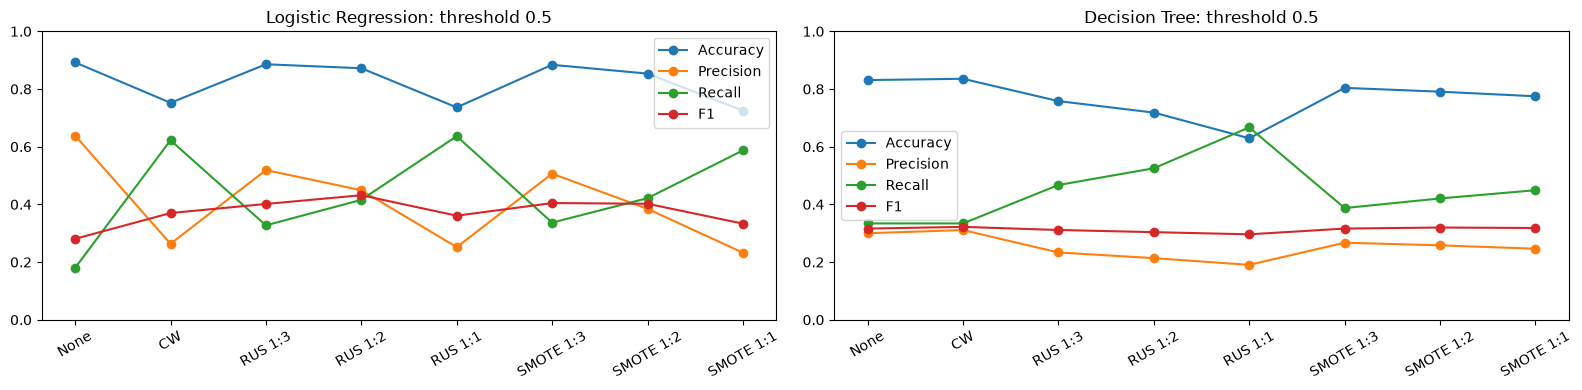

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
labels = [METHODS_EN.get(m, m) for m in METHODS_ALL]
for ax, name in zip(axes, ['Logistic Regression', 'Decision Tree']):
    sub = imb_df[imb_df['모델명'] == name].set_index('처리 방법').loc[METHODS_ALL]
    for metric in RANK_METRICS:
        ax.plot(labels, sub[metric], marker='o', label=metric)
    ax.set(title=f'{name}: threshold 0.5', ylim=(0, 1))
    ax.tick_params(axis='x', rotation=30)
    ax.legend()
plt.tight_layout()
plt.show()

#### 네 지표 변화 해석
- 개선: Logistic Regression의 Recall이 처리 없음 18.0%에서 RUS 1:1 63.7%, Class Weight 62.2%까지 약 3.5배 증가함. 실제 가입 고객 1,051명 중 찾아낸 고객이 189명에서 669명으로 늘어남.
- 부작용: 같은 구간에서 Precision은 63.9%에서 25.2%로, Accuracy는 89.2%에서 73.6%로 떨어짐. 괜히 '가입'으로 예측한 고객(FP)은 107명에서 1,988명으로 약 19배 늘어남.
- 처리 강도(1:3 → 1:2 → 1:1)가 셀수록 Recall은 오르고 Precision·Accuracy는 떨어짐 (LR RUS 기준 Recall 32.7% → 41.6% → 63.7%, Precision 51.9% → 44.9% → 25.2%).
- F1은 중간 강도에서 가장 높음: LR RUS 1:2(0.432)가 최고이고, 처리 없음(0.281)이나 RUS 1:1(0.361)은 낮음. Recall과 Precision 중 한쪽이 지나치게 낮으면 F1이 떨어지기 때문임.
- Accuracy는 처리 없음이 가장 높지만, 이는 대부분을 '미가입'으로 예측했기 때문임. 가입 고객을 더 찾을수록 Accuracy가 떨어지는 구조라 Accuracy만으로는 판단할 수 없음.
- Decision Tree: Class Weight는 거의 효과가 없음(Recall 33.4% → 32.9%). 깊이 제한 없이 자란 트리는 잎마다 한 클래스만 남아 있어 가중치를 줘도 판단이 바뀌지 않기 때문임. RUS는 Recall을 66.7%까지 올리지만 Precision이 19.0%, Accuracy가 62.9%로 떨어짐.

## 3-4. 평균 순위 비교

In [40]:
imb_df.sort_values('평균 순위').set_index('모델')[RANK_METRICS + ['평균 순위', 'PR-AUC']]

,Accuracy,Precision,Recall,F1,평균 순위,PR-AUC
모델,,,,,,
Logistic Regression | RUS 1:2,0.8720,0.4491,0.4158,0.4318,4.75,0.4001
Logistic Regression | SMOTE 1:3,0.8840,0.5064,0.3368,0.4046,5.00,0.3822
Logistic Regression | SMOTE 1:2,0.8534,0.3845,0.4215,0.4022,5.25,0.3730
Logistic Regression | RUS 1:3,0.8858,0.5189,0.3273,0.4014,5.75,0.4021
Logistic Regression | Class Weight,0.7522,0.2633,0.6223,0.3700,7.25,0.4015
Logistic Regression | RUS 1:1,0.7363,0.2518,0.6365,0.3608,8.00,0.3981
Decision Tree | Class Weight,0.8355,0.3109,0.3340,0.3220,8.38,0.1817
Logistic Regression | 처리 없음,0.8922,0.6385,0.1798,0.2806,8.50,0.4034
Decision Tree | SMOTE 1:2,0.7908,0.2580,0.4206,0.3198,9.25,0.1763


#### 평균 순위 해석
- 상위 조합은 모두 Logistic Regression의 중간 강도 처리(1:3, 1:2)임. Precision과 Recall이 모두 30~50% 수준으로 어느 한쪽이 무너지지 않음.
- LR 처리 없음(8.50)은 Accuracy·Precision은 1등권이지만 Recall이 최하위권이라 평균 순위가 낮음. 반대로 LR RUS 1:1(8.00)과 LR Class Weight(7.25)는 Recall은 높지만 Precision·Accuracy가 낮음. 극단적인 조합은 평균 순위에서 불리함.
- Decision Tree는 가장 좋은 classweight도 8.38로, 과적합 때문에 어떤 처리를 해도 LR의 상위 조합보다 낮음.
- 참고로 PR-AUC는 LR 처리 없음(0.403)과 RUS(0.398~0.402)가 거의 같고 SMOTE는 0.363~0.382로 낮음. 불균형 처리는 고객을 줄 세우는 능력보다는 '가입'으로 판단하는 기준을 바꾸는 효과가 큼.

## 3-5. Confusion Matrix 변화 (Logistic Regression)

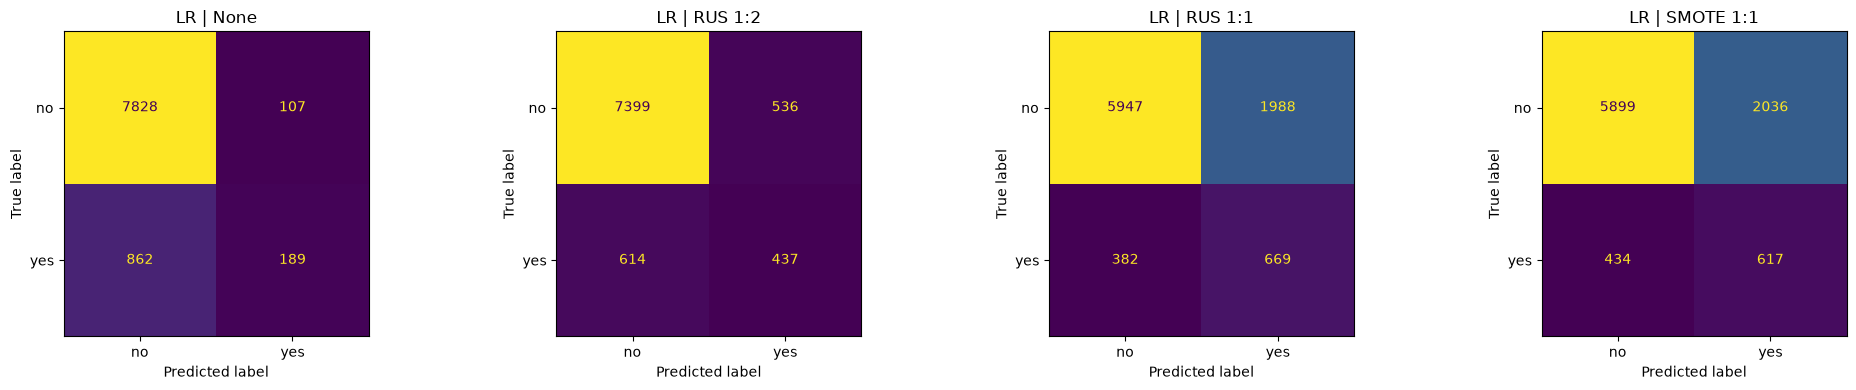

In [41]:
show = ['처리 없음', 'RUS 1:2', 'RUS 1:1', 'SMOTE 1:1']
plot_confusions(imb_probas, [('Logistic Regression', m) for m in show],
                [f'LR | {METHODS_EN.get(m, m)}' for m in show])

#### Confusion Matrix 해석

- 처리 없음은 296명에게 전화해 189명이 가입(약 64%)하지만, 가입 고객의 82%를 놓침.
- RUS 1:2는 973명에게 전화해 437명이 가입(약 45%). 처리 없음보다 가입 고객을 2.3배 찾으면서 헛걸음은 536명 수준으로 관리됨.
- RUS 1:1은 2,657명에게 전화해 669명이 가입(약 25%). 가입 고객은 가장 많이 찾지만 헛걸음이 약 2,000명으로 급증함.
- SMOTE 1:1은 RUS 1:1과 전화할 고객 수가 비슷한데 찾은 가입 고객은 53명 적어(617 vs 669), 같은 비용으로 성과가 더 낮음.

## 3-6. 불균형 처리 종합
#### 개선과 부작용
- 개선: LR의 Recall이 처리 없음 18.0%에서 최대 63.7%(RUS 1:1)까지 올라, '가입' 예측을 지나치게 아끼는 문제를 해결함.
- 부작용: 처리 강도가 셀수록 Precision·Accuracy가 급락하고 FP가 급증함 (LR RUS 1:1: Precision 25.2%, Accuracy 73.6%, FP 1,988명). SMOTE는 가짜 고객 때문에 PR-AUC까지 떨어짐.
- 기본 설정의 Decision Tree는 과적합으로 Class Weight가 거의 효과가 없고, 샘플링은 Precision을 크게 떨어뜨림.

#### 4장부터 비교 대상을 줄이는 기준
- 1:1 제외: Precision이 무너져(LR 0.252, DT 0.190) 평균 순위가 처리 없음보다도 나쁨 (LR RUS 1:1 8.00, SMOTE 1:1 9.75 vs 처리 없음 8.50).
- 1:3과 1:2 중 1:3 선택: LR은 1:2의 평균 순위가 조금 좋았지만(4.75 vs 5.75), 1:3이 Precision을 덜 희생함 (LR 0.519 vs 0.449, DT 0.233 vs 0.214). 헛걸음 통화를 줄이는 것도 중요하므로 Precision이 안정적인 1:3을 중간 단계로 남김.
- 4장 이후 비교: 처리 없음, Class Weight, RUS 1:3, SMOTE 1:3 (4가지)

# 4. 모델링
- 9개 모델 × 4가지 불균형 처리를 같은 조건에서 비교하고, Stacking Ensemble을 추가함
- 모델: Logistic Regression, KNN, Decision Tree, Random Forest, Gradient Boosting, AdaBoost, XGBoost, LightGBM, CatBoost
- 불균형 처리 4가지: 처리 없음, Class Weight, RUS 1:3, SMOTE 1:3 (3장 결과에 따라 1:2·1:1 제외)
- 공통 조건: 기본 하이퍼파라미터, 같은 Train/Validation, 임계값 0.5, 네 지표 평균 순위로 비교
- Logistic Regression·KNN에는 이상치 클리핑 + balance 로그 변환을 파이프라인 첫 단계로 적용

## 4-1. LR·KNN용 이상치 클리핑 효과
- 값의 크기·거리에 민감한 LR과 KNN에만 적용. 기준(상위 1%)은 Train에서만 계산되고, 샘플링보다 앞에 둠

In [42]:
print('Train 기준 클리핑 상한:', {k: float(v) for k, v in OutlierClipper().fit(X_train).upper_.items()})

clip_rows = []
for name in ['Logistic Regression', 'KNN']:
    for clip in [False, True]:
        res, _ = evaluate(f"{name} | {'클리핑+로그' if clip else '적용 안 함'}", build_pipeline(name, clip=clip))
        clip_rows.append(res)
pd.DataFrame(clip_rows).set_index('모델')[RANK_METRICS + ['PR-AUC']]

Train 기준 클리핑 상한: {'balance': 12956.0, 'campaign': 16.0, 'pdays': 521.0}


,Accuracy,Precision,Recall,F1,PR-AUC
모델,,,,,
Logistic Regression | 적용 안 함,0.8922,0.6385,0.1798,0.2806,0.4034
Logistic Regression | 클리핑+로그,0.8928,0.6486,0.1827,0.2851,0.4040
KNN | 적용 안 함,0.8874,0.5512,0.1998,0.2933,0.2799
KNN | 클리핑+로그,0.8870,0.5433,0.2150,0.3081,0.2854


#### 클리핑 해석
- Train 기준 클리핑 상한은 balance 12,956, campaign 16회, pdays 521일임.
- Logistic Regression: 네 지표가 모두 소폭 개선되거나 비슷함 (Precision 0.639 → 0.649, F1 0.281 → 0.285).
- KNN: Recall 0.200 → 0.215, F1 0.293 → 0.308로 소폭 개선됨.
- 개선 폭이 작은 이유는 베이스라인 Permutation Importance에서 balance, campaign, pdays의 예측 기여도가 원래 작았기 때문임. 성능을 해치지 않으므로 이후 실험에서 두 모델에 적용함.

## 4-2. 실험 설정
| 모델 | Class Weight 적용 방식 | 전처리 |
|---|---|---|
| Logistic Regression, Decision Tree, Random Forest, LightGBM | class_weight='balanced' | LR만 스케일링·클리핑 |
| KNN | 가중치 개념이 없어 Class Weight 제외 | 스케일링·클리핑 |
| Gradient Boosting, AdaBoost | 옵션이 없어 학습 시 sample_weight로 전달 (가입 약 4.27, 미가입 약 0.57) | - |
| XGBoost | scale_pos_weight = 미가입 수 ÷ 가입 수 (약 7.5, 1이면 처리 없음) | - |
| CatBoost | auto_class_weights='Balanced' | 범주형 직접 처리 (원-핫 없음) |

In [43]:
MODELS = ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'Gradient Boosting',
          'AdaBoost', 'XGBoost', 'LightGBM', 'CatBoost']
METHODS = ['처리 없음', 'Class Weight', 'RUS 1:3', 'SMOTE 1:3']
print(f'실험 조합: {len(MODELS)}개 모델 × {len(METHODS)}가지 처리 (KNN의 Class Weight 제외)')

실험 조합: 9개 모델 × 4가지 처리 (KNN의 Class Weight 제외)


## 4-3. 실험 실행
- CatBoost와 Random Forest가 가장 오래 걸림. 결과는 experiment_cache.pkl에 저장되어 다시 실행하면 이어서 진행함

In [44]:
model_df, model_probas = run_experiments(MODELS, METHODS, tag='ch4', clip=True)
print('전체 조합 수:', len(model_df))

Logistic Regression  완료 (0초)
KNN                  완료 (0초)
Decision Tree        완료 (0초)
Random Forest        완료 (0초)
Gradient Boosting    완료 (0초)
AdaBoost             완료 (0초)
XGBoost              완료 (0초)
LightGBM             완료 (0초)
CatBoost             완료 (0초)
전체 조합 수: 35


## 4-4. 처리 없음 기준 모델 비교

In [45]:
(model_df[model_df['처리 방법'] == '처리 없음'].set_index('모델명')
 [RANK_METRICS + ['PR-AUC', '학습 시간(초)']].sort_values('F1', ascending=False))

,Accuracy,Precision,Recall,F1,PR-AUC,학습 시간(초)
모델명,,,,,,
XGBoost,0.8933,0.5939,0.2769,0.3777,0.4267,0.19
LightGBM,0.8941,0.6112,0.2588,0.3636,0.4395,0.11
Random Forest,0.8922,0.5976,0.2388,0.3413,0.4108,0.81
CatBoost,0.8915,0.5913,0.2341,0.3354,0.4457,41.25
Decision Tree,0.8310,0.3000,0.3340,0.3161,0.1781,0.74
Gradient Boosting,0.8932,0.6304,0.2093,0.3143,0.4279,2.03
KNN,0.8870,0.5433,0.2150,0.3081,0.2854,0.04
Logistic Regression,0.8928,0.6486,0.1827,0.2851,0.4040,0.08
AdaBoost,0.8915,0.6357,0.1694,0.2675,0.3772,0.54


#### 처리 없음 기준 해석
- Decision Tree를 제외한 모든 모델의 Accuracy가 0.887~0.894로 Dummy(0.883)와 거의 같아, Accuracy로는 모델을 구분할 수 없음.
- 모든 모델이 Precision은 54~65%로 높지만 Recall은 17~28%로 낮음. 불균형 때문에 '가입' 예측을 매우 조심스럽게 하는 상태임.
- F1은 XGBoost(0.378), LightGBM(0.364) 순으로 높고, PR-AUC는 CatBoost(0.446), LightGBM(0.440)이 가장 높아 부스팅 계열이 고객을 가장 잘 줄 세움.

## 4-5. 지표별 비교 (모델 & 처리 방법)

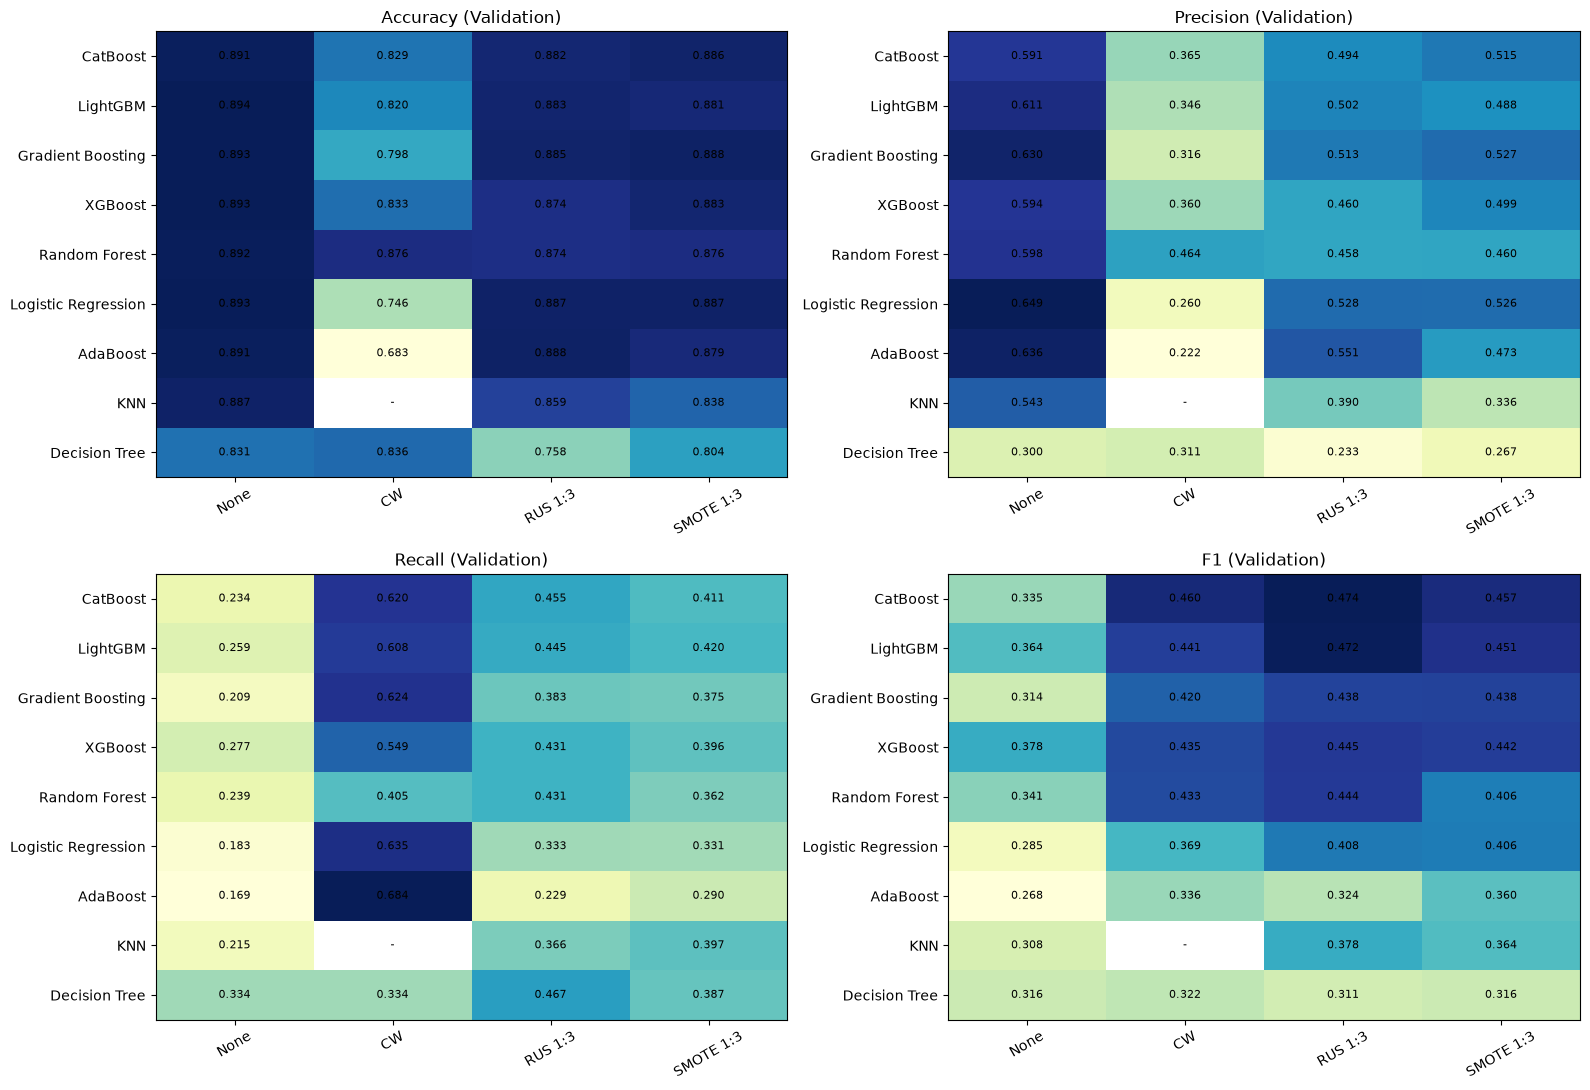

Accuracy  1등: LightGBM | 처리 없음 (0.8941)
Precision 1등: Logistic Regression | 처리 없음 (0.6486)
Recall    1등: AdaBoost | Class Weight (0.6841)
F1        1등: CatBoost | RUS 1:3 (0.4737)


In [46]:
MODEL_ORDER = ['CatBoost', 'LightGBM', 'Gradient Boosting', 'XGBoost', 'Random Forest',
               'Logistic Regression', 'AdaBoost', 'KNN', 'Decision Tree']
labels = [METHODS_EN.get(m, m) for m in METHODS]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, metric in zip(axes.ravel(), RANK_METRICS):
    plot_heatmap(model_df, metric, ax, MODEL_ORDER, METHODS, labels)
plt.tight_layout()
plt.show()

for metric in RANK_METRICS:
    top = model_df.sort_values(metric, ascending=False).iloc[0]
    print(f'{metric:9s} 1등: {top["모델"]} ({top[metric]:.4f})')

#### 지표별 해석
- 지표별 1등이 모두 다름: Accuracy는 LightGBM 처리 없음(0.894), Precision은 LR 처리 없음(0.649), Recall은 AdaBoost Class Weight(0.684), F1은 CatBoost RUS 1:3(0.474).
- Accuracy·Precision은 '조심스러운' 처리 없음, Recall은 '과감한' Class Weight에서 1등이 나와, 한 지표만 보면 판단이 한쪽으로 치우침. 그래서 네 지표의 평균 순위로 선택함.
- F1은 대부분의 모델에서 중간 강도 샘플링(RUS 1:3, SMOTE 1:3)일 때 가장 높음. Class Weight는 Recall을 크게 올리지만(0.55~0.68) Precision이 0.22~0.37로 떨어짐.

## 4-6. Stacking Ensemble
- 서로 다르게 판단하는 모델을 섞을 때 효과가 큼. 처리 없음 기준 예측 확률의 순위 상관으로 구성 모델을 고름

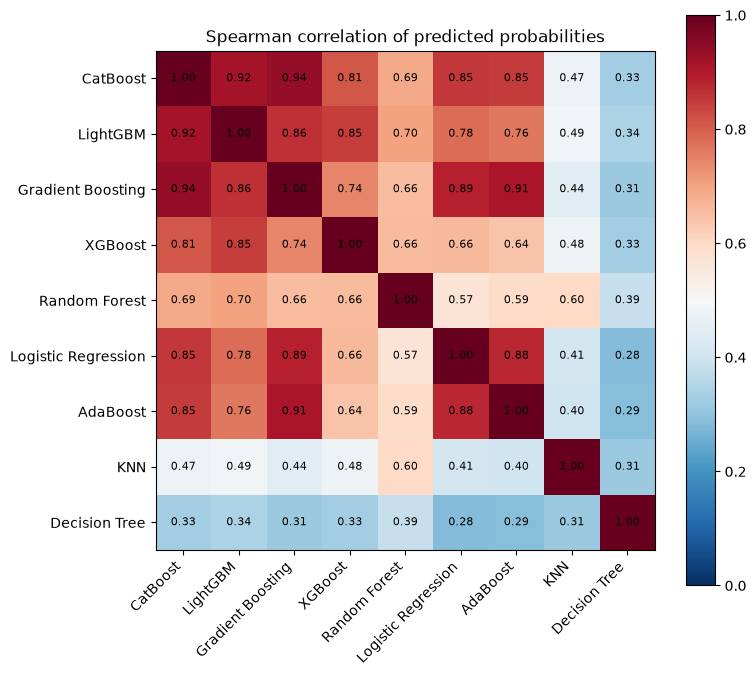

In [47]:
corr = pd.DataFrame({n: model_probas[(n, '처리 없음')] for n in MODEL_ORDER}).corr(method='spearman')

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=0, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=8)
ax.set_title('Spearman correlation of predicted probabilities')
plt.colorbar(im)
plt.tight_layout()
plt.show()

#### 예측 상관 해석 및 구성 결정
- 부스팅 계열끼리 예측이 매우 비슷함 (Gradient Boosting–AdaBoost 약 0.91, LightGBM–XGBoost·Gradient Boosting 약 0.85~0.86, CatBoost–LightGBM 약 0.92). 부스팅을 여러 개 넣어도 비슷한 판단이 겹침.
- Random Forest는 LightGBM과 약 0.70으로 다르게 판단하는 편이라 다양성을 더해줌.
- 구성 A: Logistic Regression(선형) + Random Forest(배깅) + LightGBM(부스팅 대표). CatBoost를 넣은 구성은 5장에서 따로 확인함.

In [48]:
def make_stacking(members, method='처리 없음'):
    """구성 모델의 예측 확률을 5겹 교차검증으로 만들어 최종 LR이 판단. 샘플링은 Stacking 전체 앞에 둠"""
    stack = StackingClassifier(
        estimators=[(m.replace(' ', '_'), build_pipeline(m, clip=True)) for m in members],
        final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        stack_method='predict_proba')
    sampler = make_sampler(method)
    return ImbPipeline(([('sampler', sampler)] if sampler else []) + [('stack', stack)])

STACK_A = ['Logistic Regression', 'Random Forest', 'LightGBM']
stack_rows = []
for method in ['처리 없음', 'RUS 1:3']:
    def job():
        pipe = make_stacking(STACK_A, method)
        res, proba = evaluate(f'Stacking A | {method}', pipe)
        weights = dict(zip(STACK_A, pipe.named_steps['stack'].final_estimator_.coef_[0].round(2)))
        return res, proba, weights
    res, proba, weights = cached(('ch4', 'Stacking A', method), job)
    stack_rows.append({**res, '모델명': 'Stacking A', '처리 방법': method})
    model_probas[('Stacking A', method)] = proba
    print(f'Stacking A | {method} 최종 모델 가중치: {weights}')

stack_df = pd.DataFrame(stack_rows)
stack_df.set_index('모델')[RANK_METRICS + ['PR-AUC', '학습 시간(초)']]

Stacking A | 처리 없음 최종 모델 가중치: {'Logistic Regression': np.float64(0.59), 'Random Forest': np.float64(2.17), 'LightGBM': np.float64(3.56)}
Stacking A | RUS 1:3 최종 모델 가중치: {'Logistic Regression': np.float64(0.89), 'Random Forest': np.float64(1.51), 'LightGBM': np.float64(2.98)}


,Accuracy,Precision,Recall,F1,PR-AUC,학습 시간(초)
모델,,,,,,
Stacking A | 처리 없음,0.8944,0.6209,0.2493,0.3557,0.4461,5.22
Stacking A | RUS 1:3,0.8827,0.4984,0.4415,0.4682,0.4331,2.76


#### Stacking 해석
- 처리 없음: PR-AUC 0.446으로 전체 조합 중 가장 높지만, 다른 모델처럼 Recall이 0.249로 낮음 (F1 0.356).
- RUS 1:3: Precision 0.498, Recall 0.442, F1 0.468로 LightGBM 단독(0.472)과 거의 같음.
- 최종 모델 가중치는 LightGBM(약 3)과 Random Forest(1.5~2.2)가 대부분을 차지하고 LR은 작음. 학습 시간은 39~92초로 LightGBM(0.2초)보다 훨씬 김.

## 4-7. 평균 순위로 최종 비교

In [49]:
all_df = add_avg_rank(pd.concat([model_df, stack_df], ignore_index=True))
print('전체 조합 수:', len(all_df))
all_df.sort_values('평균 순위').set_index('모델')[RANK_METRICS + ['평균 순위', 'PR-AUC', 'TP', 'FP']].head(10)

전체 조합 수: 37


,Accuracy,Precision,Recall,F1,평균 순위,PR-AUC,TP,FP
모델,,,,,,,,
LightGBM | RUS 1:3,0.8834,0.5016,0.4453,0.4718,10.75,0.4267,468,465
CatBoost | RUS 1:3,0.8818,0.4943,0.4548,0.4737,11.75,0.4357,478,489
CatBoost | SMOTE 1:3,0.8858,0.5149,0.4110,0.4571,11.75,0.4285,432,407
Stacking A | RUS 1:3,0.8827,0.4984,0.4415,0.4682,12.25,0.4331,464,467
Gradient Boosting | SMOTE 1:3,0.8876,0.5274,0.3749,0.4383,13.25,0.4153,394,353
XGBoost | 처리 없음,0.8933,0.5939,0.2769,0.3777,14.50,0.4267,291,199
LightGBM | SMOTE 1:3,0.8807,0.4884,0.4196,0.4514,14.75,0.4180,441,462
LightGBM | 처리 없음,0.8941,0.6112,0.2588,0.3636,14.75,0.4395,272,173
Stacking A | 처리 없음,0.8944,0.6209,0.2493,0.3557,15.00,0.4461,262,160


In [50]:
print('처리 방법별 평균 순위 (9개 모델 평균)')
display(all_df[all_df['모델명'].isin(MODELS)].groupby('처리 방법')['평균 순위'].mean().loc[METHODS].round(1))

print('모델별 최고 조합')
(all_df.sort_values('평균 순위').groupby('모델명').head(1)
 .set_index('모델명')[['처리 방법'] + RANK_METRICS + ['평균 순위', 'PR-AUC', '학습 시간(초)']])

처리 방법별 평균 순위 (9개 모델 평균)


처리 방법
처리 없음           19.6
Class Weight    21.4
RUS 1:3         17.6
SMOTE 1:3       18.8
Name: 평균 순위, dtype: float64

모델별 최고 조합


,처리 방법,Accuracy,Precision,Recall,F1,평균 순위,PR-AUC,학습 시간(초)
모델명,,,,,,,,
LightGBM,RUS 1:3,0.8834,0.5016,0.4453,0.4718,10.75,0.4267,0.08
CatBoost,RUS 1:3,0.8818,0.4943,0.4548,0.4737,11.75,0.4357,40.94
Stacking A,RUS 1:3,0.8827,0.4984,0.4415,0.4682,12.25,0.4331,2.76
Gradient Boosting,SMOTE 1:3,0.8876,0.5274,0.3749,0.4383,13.25,0.4153,3.18
XGBoost,처리 없음,0.8933,0.5939,0.2769,0.3777,14.50,0.4267,0.19
Logistic Regression,RUS 1:3,0.8872,0.5279,0.3330,0.4084,15.75,0.4023,0.05
Random Forest,처리 없음,0.8922,0.5976,0.2388,0.3413,17.25,0.4108,0.81
AdaBoost,RUS 1:3,0.8880,0.5515,0.2293,0.3239,20.00,0.3688,0.24
KNN,처리 없음,0.8870,0.5433,0.2150,0.3081,22.75,0.2854,0.04


#### 평균 순위 해석 (37개 조합)

- 처리 방법별 평균 순위: RUS 1:3(17.6) < SMOTE 1:3(18.8) < 처리 없음(19.6) < Class Weight(21.4). 중간 강도 샘플링이 가장 좋고, Class Weight가 가장 낮음.
- 모델별 최고 조합: RUS 1:3이 6개(LightGBM, CatBoost, LR, AdaBoost, DT, Stacking A), SMOTE 1:3이 1개(Gradient Boosting), 처리 없음이 3개(XGBoost, Random Forest, KNN).
- 상위 1~4위의 평균 순위 차이가 1.5 이내로 작아 LightGBM부터 Stacking A까지는 사실상 비슷한 수준임.

## 4-8. 모델별로 불균형 처리 효과가 다른 이유

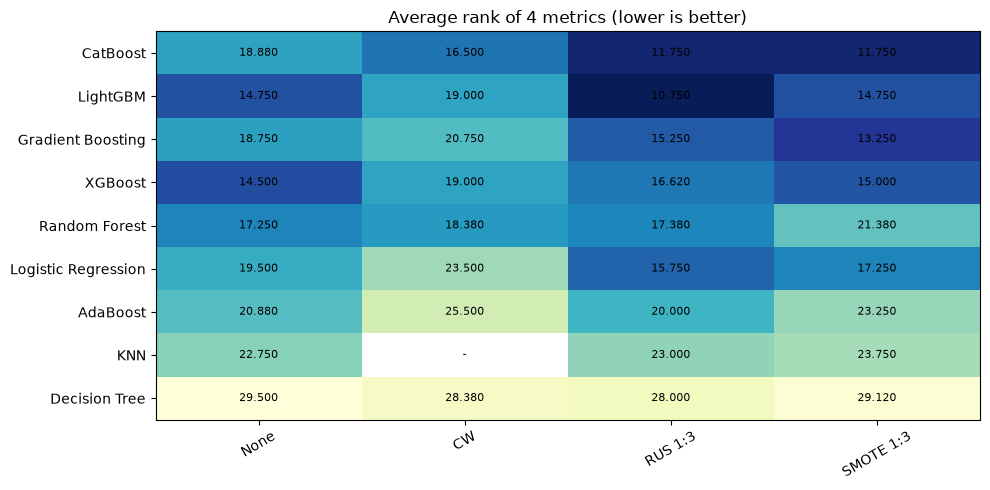

In [51]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_heatmap(all_df[all_df['모델명'].isin(MODELS)], '평균 순위', ax, MODEL_ORDER, METHODS, labels, cmap='YlGnBu_r')
ax.set_title('Average rank of 4 metrics (lower is better)')
plt.tight_layout()
plt.show()

#### 모델별 차이 해석
- 부스팅 계열 (LightGBM, CatBoost, Gradient Boosting): RUS 1:3에서 F1이 크게 오름 (LightGBM 0.364 → 0.472, CatBoost 0.335 → 0.474). 확률을 촘촘하게 잘 줄 세우기 때문에, 약간의 처리로 '가입' 기준만 낮춰도 Precision을 크게 잃지 않고 Recall을 올릴 수 있음.
- Random Forest: Class Weight가 효과가 없음(Recall 0.239 → 0.206). 끝까지 자란 트리는 잎마다 한 클래스만 남아 가중치가 판단을 바꾸지 못함. 데이터를 바꾸는 RUS 1:3에서는 F1이 0.341 → 0.444로 오름.
- AdaBoost: Class Weight에서 Recall이 0.684로 크게 오르지만 Precision이 0.222로 떨어짐. 얕은 트리로 판단해 확률이 거칠어, 가중치가 기준을 한꺼번에 크게 옮김.
- KNN: 평균 순위로는 처리 없음이 가장 좋음. RUS로 미가입을 줄이면 Recall은 오르지만 Precision이 크게 떨어져, 네 지표의 균형은 오히려 나빠짐.
- Decision Tree: 과적합으로 어떤 처리에서도 하위권임.

## 4-9. 최종 후보 상세 비교

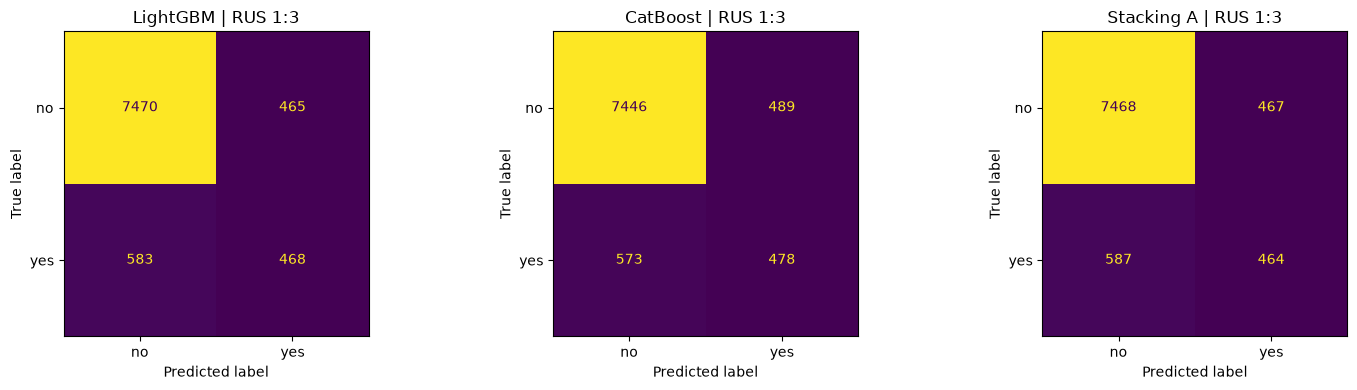

,,Accuracy,Precision,Recall,F1,평균 순위,PR-AUC,TP,FP,FN,학습 시간(초)
모델명,처리 방법,,,,,,,,,,
LightGBM,RUS 1:3,0.8834,0.5016,0.4453,0.4718,10.75,0.4267,468,465,583,0.08
CatBoost,RUS 1:3,0.8818,0.4943,0.4548,0.4737,11.75,0.4357,478,489,573,40.94
Stacking A,RUS 1:3,0.8827,0.4984,0.4415,0.4682,12.25,0.4331,464,467,587,2.76


In [52]:
FINALISTS = [('LightGBM', 'RUS 1:3'), ('CatBoost', 'RUS 1:3'), ('Stacking A', 'RUS 1:3')]
plot_confusions(model_probas, FINALISTS, [f'{n} | {m}' for n, m in FINALISTS])
all_df.set_index(['모델명', '처리 방법']).loc[FINALISTS][RANK_METRICS + ['평균 순위', 'PR-AUC', 'TP', 'FP', 'FN', '학습 시간(초)']]

#### 최종 후보 해석
| 후보 | TP (찾은 가입) | FP (헛걸음) | FN (놓친 가입) | 전화할 고객 수 |
|---|---|---|---|---|
| LightGBM, RUS 1:3 | 468 | 465 | 583 | 933 |
| CatBoost, RUS 1:3 | 478 | 489 | 573 | 967 |
| Stacking A, RUS 1:3 | 464 | 467 | 587 | 931 |

- 세 후보 모두 약 930~970명에게 전화해 약 470명이 가입함(2명 중 1명). 가입 고객의 약 45%를 찾음.
- 베이스라인 LR(전화 296명, 가입 189명)보다 가입 고객을 약 2.5배 더 찾으면서 Precision은 약 50%를 유지함.
- 성능이 거의 같으므로 학습 시간이 0.2초인 LightGBM이 운영에 가장 유리함.

## 4-10. 모델링 종합
- 네 지표 평균 순위로 LightGBM RUS 1:3이 1위, CatBoost RUS 1:3(F1 1위 0.474)과 Stacking A RUS 1:3이 공동 2위.
- 불균형 처리는 RUS 1:3이 가장 균형이 좋고, Class Weight는 Recall은 높지만 Precision이 크게 떨어짐.
- 모델별로 효과가 다름: 부스팅은 중간 강도 처리로 크게 개선, 끝까지 자란 트리는 Class Weight 효과 없음, KNN은 불균형 처리를 해도 네 지표의 균형이 오히려 나빠짐.
- 다음: 5장에서 피처 엔지니어링과 CatBoost 포함 Stacking으로 추가 개선 가능성을 확인함.

# 5. 추가 실험: 피처 엔지니어링, CatBoost 포함 Stacking
- 4장 결과를 개선할 수 있는지 두 방향으로 확인함 (모두 RUS 1:3, Validation)
  1. 서로 연관성이 높은 칼럼을 묶은 새 피처
  2. CatBoost를 포함한 Stacking

## 5-1. 칼럼 쌍의 연관성 (Train)
- 범주형끼리: Cramér's V / 범주형–수치형: 상관비(eta) / 수치형끼리: 스피어만 순위 상관의 절댓값 (모두 0~1, 1에 가까울수록 비슷한 정보)

In [53]:
def cramers_v(a, b):
    t = pd.crosstab(a, b)
    return np.sqrt(chi2_contingency(t)[0] / (t.values.sum() * (min(t.shape) - 1)))

def eta(cat_s, num_s):
    g, m = num_s.groupby(cat_s), num_s.mean()
    return np.sqrt(((g.mean() - m) ** 2 * g.size()).sum() / ((num_s - m) ** 2).sum())

pairs = []
for i, a in enumerate(CAT_COLS):
    for b in CAT_COLS[i + 1:]:
        pairs.append((a, b, "Cramér's V", cramers_v(X_train[a], X_train[b])))
    for b in NUM_COLS:
        pairs.append((a, b, 'eta', eta(X_train[a], X_train[b])))
for i, a in enumerate(NUM_COLS):
    for b in NUM_COLS[i + 1:]:
        pairs.append((a, b, 'spearman', abs(X_train[a].corr(X_train[b], method='spearman'))))

pd.DataFrame(pairs, columns=['칼럼 A', '칼럼 B', '방법', '연관성']).sort_values('연관성', ascending=False).head(10).round(3)

,칼럼 A,칼럼 B,방법,연관성
104,pdays,previous,spearman,0.986
82,poutcome,pdays,eta,0.883
83,poutcome,previous,eta,0.647
7,job,education,Cramér's V,0.559
60,contact,month,Cramér's V,0.511
41,housing,month,Cramér's V,0.507
8,job,age,eta,0.497
73,month,day,eta,0.447
21,marital,age,eta,0.435
75,month,pdays,eta,0.284


#### 연관성 해석 및 새 피처 선정
| 순위 | 칼럼 쌍 | 연관성 | 판단 |
|---|---|---|---|
| 1 | pdays – previous | 0.99 | 둘 다 '이전 연락 여부'를 담고 있어 묶을 의미 있음 |
| 2 | poutcome – pdays | 0.88 | 위와 같은 그룹 |
| 3 | job – education | 0.56 | 사회경제적 수준으로 묶을 의미 있음 |
| 4 | contact – month | 0.51 | 5·6월 기록 누락에 따른 관계라 데이터 수집 문제에 가까움 → 제외 |
| 5 | housing – month | 0.51 | 캠페인 일정에 따른 관계로 의미 약함 → 제외 |
| 6 | job – age | 0.50 | 직업별 생애 단계로 묶을 의미 있음 |

- 의미가 분명한 세 그룹으로 새 피처 3개를 만듦
  - age_job_gap: 나이 − 같은 직업의 중앙 나이(Train 기준). 같은 직업 안에서 젊은 편인지 나이 든 편인지 (예: 55세 은퇴자는 조기 은퇴)
  - prev_history: 이전 캠페인 결과 + 경과 기간(180일 이내 recent / 이후 old / 이전 연락 없음 none). 이전 이력을 하나로 요약
  - job_edu: 직업 + 학력 조합 (예: management_tertiary)
- age_job_gap은 직업별 중앙 나이를 계산하므로 Pipeline 안에 넣어 Train에서만 fit되도록 함

## 5-2. 새 피처 실험

In [54]:
class PairFeatures(BaseEstimator, TransformerMixin):
    """연관성 높은 칼럼을 묶은 새 피처 (age_job_gap의 직업별 중앙 나이는 Train에서만 계산)"""
    def __init__(self, use=('age_job_gap', 'prev_history', 'job_edu')):
        self.use = use

    def fit(self, X, y=None):
        self.job_age_ = X.groupby('job')['age'].median()
        return self

    def transform(self, X):
        X = X.copy()
        if 'age_job_gap' in self.use:
            X['age_job_gap'] = X['age'] - X['job'].map(self.job_age_)
        if 'prev_history' in self.use:
            recency = np.where(X['pdays'] == -1, 'none', np.where(X['pdays'] <= 180, 'recent', 'old'))
            X['prev_history'] = np.where(recency == 'none', 'none', X['poutcome'] + '_' + recency)
        if 'job_edu' in self.use:
            X['job_edu'] = X['job'] + '_' + X['education']
        return X

FE_CONFIGS = {'기존': (), '+ age_job_gap': ('age_job_gap',), '+ prev_history': ('prev_history',),
              '+ job_edu': ('job_edu',), '+ 3개 모두': ('age_job_gap', 'prev_history', 'job_edu')}
FE_MODELS = ['Logistic Regression', 'LightGBM', 'CatBoost']

fe_rows = []
for name in FE_MODELS:
    for label, use in FE_CONFIGS.items():
        extra_num = [c for c in use if c == 'age_job_gap']
        extra_cat = [c for c in use if c != 'age_job_gap']
        def job():
            pipe = build_pipeline(name, 'RUS 1:3', clip=True, extra_num=extra_num, extra_cat=extra_cat,
                                  pre_steps=[('pair', PairFeatures(use))] if use else [])
            return evaluate(f'{name} | {label}', pipe)[0]
        fe_rows.append({**cached(('ch5_fe', name, label), job), '모델명': name, '피처': label})
    print(f'{name:20s} 완료')

fe_df = pd.DataFrame(fe_rows)
print('F1 (RUS 1:3, Validation)')
display(fe_df.pivot(index='모델명', columns='피처', values='F1').reindex(index=FE_MODELS, columns=list(FE_CONFIGS)))
print('PR-AUC (RUS 1:3, Validation)')
fe_df.pivot(index='모델명', columns='피처', values='PR-AUC').reindex(index=FE_MODELS, columns=list(FE_CONFIGS))

Logistic Regression  완료
LightGBM             완료
CatBoost             완료
F1 (RUS 1:3, Validation)


피처,기존,+ age_job_gap,+ prev_history,+ job_edu,+ 3개 모두
모델명,,,,,
Logistic Regression,0.4084,0.4075,0.4070,0.4075,0.4065
LightGBM,0.4718,0.4713,0.4625,0.4714,0.4585
CatBoost,0.4737,0.4759,0.4725,0.4728,0.4699


PR-AUC (RUS 1:3, Validation)


피처,기존,+ age_job_gap,+ prev_history,+ job_edu,+ 3개 모두
모델명,,,,,
Logistic Regression,0.4023,0.4025,0.4045,0.4008,0.4033
LightGBM,0.4267,0.4286,0.4243,0.4242,0.4212
CatBoost,0.4357,0.4342,0.4343,0.4346,0.4340


#### 피처 엔지니어링 해석
- 새 피처로는 일관된 성능 향상이 없었음. LR은 0.407~0.408로 변화 없음, LightGBM은 변화가 없거나 하락(3개 모두 0.459), CatBoost는 age_job_gap에서 0.474 → 0.476으로 측정 오차 수준.
- 이유: 연관성이 높은 두 칼럼은 이미 비슷한 정보를 담고 있어 묶어도 새 정보가 거의 없고(직업–학력 Cramér's V 0.56), 트리 모델은 이런 조합을 스스로 학습함. 겹치는 정보를 여러 번 넣으면 오히려 학습이 흔들림.
- 결론: 최종 모델에서 제외함. 새 피처는 '기존 칼럼에 없던 새로운 정보'를 담아야 효과가 있음 (6장).

## 5-3. CatBoost를 포함한 Stacking

In [55]:
STACK_CAT = {'Stacking LGBM+Cat': ['LightGBM', 'CatBoost'],
             'Stacking A+Cat':    STACK_A + ['CatBoost']}
cat_stack_rows = []
for label, members in STACK_CAT.items():
    def job():
        pipe = make_stacking(members, 'RUS 1:3')
        res, proba = evaluate(f'{label} | RUS 1:3', pipe)
        return res, proba, dict(zip(members, pipe.named_steps['stack'].final_estimator_.coef_[0].round(2)))
    res, proba, weights = cached(('ch5_stack', label), job)
    cat_stack_rows.append(res)
    print(f'{label} 최종 모델 가중치: {weights}')

for other in ['LightGBM', 'Random Forest', 'Logistic Regression']:
    r = pd.Series(model_probas[('CatBoost', 'RUS 1:3')]).corr(pd.Series(model_probas[(other, 'RUS 1:3')]), method='spearman')
    print(f'CatBoost vs {other:20s} 예측 순위 상관: {r:.3f}')

ref = all_df.set_index(['모델명', '처리 방법']).loc[[('CatBoost', 'RUS 1:3'), ('LightGBM', 'RUS 1:3'), ('Stacking A', 'RUS 1:3')]]
pd.concat([ref.reset_index(), pd.DataFrame(cat_stack_rows)]).set_index('모델')[RANK_METRICS + ['PR-AUC', '학습 시간(초)']]

Stacking LGBM+Cat 최종 모델 가중치: {'LightGBM': np.float64(1.85), 'CatBoost': np.float64(3.25)}
Stacking A+Cat 최종 모델 가중치: {'Logistic Regression': np.float64(0.27), 'Random Forest': np.float64(0.86), 'LightGBM': np.float64(1.46), 'CatBoost': np.float64(2.69)}
CatBoost vs LightGBM             예측 순위 상관: 0.916
CatBoost vs Random Forest        예측 순위 상관: 0.759
CatBoost vs Logistic Regression  예측 순위 상관: 0.841


,Accuracy,Precision,Recall,F1,PR-AUC,학습 시간(초)
모델,,,,,,
CatBoost | RUS 1:3,0.8818,0.4943,0.4548,0.4737,0.4357,40.94
LightGBM | RUS 1:3,0.8834,0.5016,0.4453,0.4718,0.4267,0.08
Stacking A | RUS 1:3,0.8827,0.4984,0.4415,0.4682,0.4331,2.76
Stacking LGBM+Cat | RUS 1:3,0.8823,0.4963,0.4462,0.4699,0.4392,214.45
Stacking A+Cat | RUS 1:3,0.8820,0.4953,0.4481,0.4705,0.4385,248.63


#### CatBoost 포함 Stacking 해석
- CatBoost를 넣은 Stacking의 F1은 0.470~0.471로 CatBoost 단독(0.474)보다 낮고, 학습 시간은 107~148초로 5~7배임.
- CatBoost와 LightGBM의 예측 순위 상관이 0.916으로 같은 고객을 거의 같은 순서로 줄 세워, 섞어도 서로의 실수를 보완하지 못함. 최종 가중치도 CatBoost가 2.7~3.3으로 대부분을 차지함.

## 5-4. 추가 실험 종합
- 피처 엔지니어링(칼럼 결합)과 CatBoost 포함 Stacking 모두 성능을 높이지 못함.
- 4~5장의 모든 시도에서 F1이 약 0.47에 머물러, 모델이 아니라 데이터가 담은 정보량의 한계로 판단함 → 6장에서 새로운 정보를 담은 피처로 접근함.

# 6. 캠페인 운영 피처 (연락 날짜 기반)
- 5장까지 F1이 약 0.47~0.49에서 멈춰, 모델보다 데이터가 담은 정보량의 한계로 판단함
- 고객 한 명의 정보가 아니라 '캠페인 운영 상황'이라는 새로운 정보를 피처로 추가함
- 데이터 출처(UCI) 설명에 bank-full.csv가 2008년 5월 ~ 2010년 11월 날짜순으로 정렬되어 있다고 명시되어 있어, 행 순서로 연도를 복원해 실제 연락 날짜를 만듦

## 6-1. 연락 날짜 복원 및 피처 생성
| 피처 | 만드는 방법 | 의미 |
|---|---|---|
| daily_calls | 같은 날짜에 연락한 고객 수 | 그날 캠페인 규모 (대량 연락일인지, 소수 선별 연락일인지) |
| weekly_calls | 같은 주에 연락한 고객 수 | 그 주의 캠페인 규모 |
| day_of_week | 연락 요일 (0 = 월요일) | 요일 효과 확인용 |

- 가입 여부(y)는 사용하지 않으므로 정답이 새는 누수는 없음
- 실제 운영에서는 '캠페인 계획상 그날·그 주에 연락할 예정인 고객 수'로 정의함 (예측 시점에 알 수 있는 정보)
- 연도 자체는 미래 연도에 쓸 수 없으므로 피처로 쓰지 않음

In [56]:
month_map = {m: i + 1 for i, m in enumerate(['jan', 'feb', 'mar', 'apr', 'may', 'jun',
                                                'jul', 'aug', 'sep', 'oct', 'nov', 'dec'])}
df_cal = pd.read_csv('bank-full.csv', sep=';')                       # 원본 행 순서 그대로
df_cal['month_num'] = df_cal['month'].map(month_map)
df_cal['year'] = 2008 + (df_cal['month_num'].diff() < -3).cumsum()  # 월이 크게 되돌아가면 다음 해
df_cal['date'] = pd.to_datetime(dict(year=df_cal['year'], month=df_cal['month_num'], day=df_cal['day']))
print('복원한 기간:', df_cal['date'].min().date(), '~', df_cal['date'].max().date())

df_cal['day_of_week'] = df_cal['date'].dt.dayofweek.astype(str)
df_cal['daily_calls'] = df_cal.groupby('date')['date'].transform('size')
df_cal['weekly_calls'] = df_cal.groupby(df_cal['date'].dt.to_period('W'))['date'].transform('size')

# 1-4와 같은 방식(duration 제거 + 중복 제거)으로 정리해 X와 행을 맞춤
CAL_NUM, CAL_CAT = ['daily_calls', 'weekly_calls'], ['day_of_week']
helper = ['month_num', 'year', 'date'] + CAL_NUM + CAL_CAT
cal = df_cal.loc[~df_cal.drop(columns=['duration'] + helper).duplicated()].reset_index(drop=True)
assert cal[X.columns].equals(X), 'X와 행이 일치하지 않음'

X_train6, X_val6, X_test6 = X_train.copy(), X_val.copy(), X_test.copy()
for data in [X_train6, X_val6, X_test6]:
    data[CAL_NUM + CAL_CAT] = cal.loc[data.index, CAL_NUM + CAL_CAT].values
X_train6[CAL_NUM] = X_train6[CAL_NUM].astype(int)
X_val6[CAL_NUM] = X_val6[CAL_NUM].astype(int)
X_test6[CAL_NUM] = X_test6[CAL_NUM].astype(int)
X_train6[CAL_NUM + CAL_CAT].describe(include='all').round(1)

복원한 기간: 2008-05-05 ~ 2010-11-17


,daily_calls,weekly_calls,day_of_week
count,26930.0,26930.0,26930
unique,NaN,NaN,7
top,NaN,NaN,3
freq,NaN,NaN,5766
mean,356.8,1569.2,NaN
std,198.4,912.8,NaN
min,1.0,2.0,NaN
25%,257.0,1133.0,NaN
50%,357.0,1612.0,NaN
75%,482.0,2006.0,NaN


## 6-2. 새 피처와 가입률의 관계 (Train)

In [57]:
print('하루 연락 건수 구간별 가입률')
display(y_train.groupby(pd.qcut(X_train6['daily_calls'], 5), observed=True).agg(고객수='size', 가입률='mean').round(3))

print('주별 연락 건수 구간별 가입률')
display(y_train.groupby(pd.qcut(X_train6['weekly_calls'], 5), observed=True).agg(고객수='size', 가입률='mean').round(3))

print('daily_calls와 weekly_calls의 순위 상관:',
      round(X_train6['daily_calls'].corr(X_train6['weekly_calls'], method='spearman'), 3))

print('요일별 가입률 (0 = 월요일)')
y_train.groupby(X_train6['day_of_week']).agg(고객수='size', 가입률='mean').round(3)

하루 연락 건수 구간별 가입률


,고객수,가입률
daily_calls,,
"(0.999, 229.0]",5506,0.352
"(229.0, 317.0]",5284,0.074
"(317.0, 398.0]",5485,0.046
"(398.0, 508.0]",5440,0.047
"(508.0, 825.0]",5215,0.061


주별 연락 건수 구간별 가입률


,고객수,가입률
weekly_calls,,
"(1.999, 740.0]",5560,0.347
"(740.0, 1439.0]",5738,0.067
"(1439.0, 1790.0]",5889,0.049
"(1790.0, 2038.0]",4685,0.056
"(2038.0, 3531.0]",5058,0.056


daily_calls와 weekly_calls의 순위 상관: 0.755
요일별 가입률 (0 = 월요일)


,고객수,가입률
day_of_week,,
0,5654,0.105
1,4937,0.122
2,5340,0.123
3,5766,0.125
4,5206,0.111
5,17,0.118
6,10,0.000


#### 가입률 관계 해석
- 하루 연락 건수가 가장 적은 구간(229건 이하)의 가입률이 35.2%로, 나머지 구간(4.6~7.4%)보다 5배 이상 높음.
- 대량으로 연락한 날과, 가능성 있는 고객만 골라 소수에게 연락한 날의 차이로 해석할 수 있음. 기존 칼럼 어디에도 없던 정보임.
- 요일은 주말 연락이 거의 없고(토·일 합쳐 수십 건), 평일 간 가입률 차이가 크지 않음.
- 주별 연락 건수도 같은 패턴을 보임: 연락이 가장 적은 주(740건 이하)의 가입률이 34.7%로, 나머지 구간(4.9~6.7%)보다 5배 이상 높음.
- 두 피처의 순위 상관은 0.755로 높지만 완전히 같지는 않음. 하루 건수는 그날의 상황을, 주별 건수는 그 주 캠페인의 전체 규모를 담고 있어 서로 보완하는 것으로 보이며, 실제로 최종 모델(8-5)에서 weekly_calls와 daily_calls가 피처 중요도 1·2위를 차지함.

## 6-3. 모델 비교 (기존 피처 vs 새 피처)
- 4장 상위 모델인 LightGBM, CatBoost에 새 피처를 추가해 비교 (RUS 1:3, 임계값 0.5, Validation)

In [58]:
FEATURE_SETS = {'기존': ([], []), '+ daily·weekly': (CAL_NUM, []), '+ daily·weekly·요일': (CAL_NUM, CAL_CAT)}
rows6, probas6 = [], {}
for set_name, (en, ec) in FEATURE_SETS.items():
    cols = list(X.columns) + en + ec
    df_, pr_ = run_experiments(['LightGBM', 'CatBoost'], ['RUS 1:3'], tag=f'ch6 {set_name}',
                               X_tr=X_train6[cols], X_ev=X_val6[cols], extra_num=en, extra_cat=ec)
    rows6.append(df_.assign(피처=set_name))
    probas6.update({(n, set_name): p for (n, _), p in pr_.items()})

res6 = pd.concat(rows6, ignore_index=True)
res6['모델'] = res6['모델명'] + ' | ' + res6['피처']
res6.set_index('모델')[RANK_METRICS + ['PR-AUC', 'TP', 'FP', '학습 시간(초)']]

LightGBM             완료 (0초)
CatBoost             완료 (0초)
LightGBM             완료 (0초)
CatBoost             완료 (0초)
LightGBM             완료 (0초)
CatBoost             완료 (0초)


,Accuracy,Precision,Recall,F1,PR-AUC,TP,FP,학습 시간(초)
모델,,,,,,,,
LightGBM | 기존,0.8834,0.5016,0.4453,0.4718,0.4267,468,465,0.13
CatBoost | 기존,0.8818,0.4943,0.4548,0.4737,0.4357,478,489,44.95
LightGBM | + daily·weekly,0.8811,0.4924,0.5262,0.5087,0.4601,553,570,0.11
CatBoost | + daily·weekly,0.8815,0.4938,0.5281,0.5103,0.4637,555,569,41.46
LightGBM | + daily·weekly·요일,0.8799,0.4876,0.5233,0.5048,0.4596,550,578,0.13
CatBoost | + daily·weekly·요일,0.8797,0.4868,0.5252,0.5053,0.4689,552,582,40.61


#### 모델 비교 해석
| 모델 | 피처 | Precision | Recall | F1 | PR-AUC |
|---|---|---|---|---|---|
| LightGBM | 기존 | 0.502 | 0.445 | 0.472 | 0.427 |
| LightGBM | + daily·weekly | 0.492 | 0.526 | 0.509 | 0.460 |
| CatBoost | 기존 | 0.494 | 0.455 | 0.474 | 0.436 |
| CatBoost | + daily·weekly | 0.494 | 0.528 | 0.510 | 0.464 |

- daily_calls·weekly_calls를 추가하자 두 모델 모두 F1이 약 0.036 올라 처음으로 0.5를 넘음. 임계값 조정 없이 0.5 기준 결과임.
- PR-AUC도 0.427~0.436에서 0.460~0.464로 올라, 고객을 줄 세우는 능력 자체가 좋아짐. 판단 기준만 옮긴 것이 아니라 새로운 정보가 더해진 효과임.
- Precision은 그대로(약 0.49)이면서 Recall이 약 0.45 → 0.53으로 올라, 헛걸음은 크게 늘리지 않고 가입 고객을 약 80명 더 찾음 (LightGBM TP 468 → 553).
- 요일을 추가하면 두 모델 모두 0.505로 오히려 조금 낮아, 요일은 사용하지 않음.

## 6-4. 교차검증으로 개선 재확인 (Train 5겹, LightGBM, RUS 1:3)

In [59]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for set_name, (en, ec) in FEATURE_SETS.items():
    cols = list(X.columns) + en + ec
    pipe = build_pipeline('LightGBM', 'RUS 1:3', extra_num=en, extra_cat=ec)
    scores = cross_val_score(pipe, X_train6[cols], y_train, cv=cv5, scoring='f1')
    cv_rows.append([set_name, round(scores.mean(), 4)] + list(np.round(scores, 3)))
pd.DataFrame(cv_rows, columns=['피처', 'CV F1 평균'] + [f'fold{i}' for i in range(1, 6)]).set_index('피처')

,CV F1 평균,fold1,fold2,fold3,fold4,fold5
피처,,,,,,
기존,0.4644,0.450,0.438,0.500,0.475,0.460
+ daily·weekly,0.5045,0.483,0.513,0.519,0.500,0.507
+ daily·weekly·요일,0.5094,0.494,0.507,0.541,0.509,0.496


#### 교차검증 해석
- daily·weekly 추가 시 CV F1이 0.464 → 0.505로 평균 0.041 오르고, 5개 fold 모두에서 개선됨 (fold별 +0.019 ~ +0.075).
- 요일까지 넣으면 0.509로 조금 더 높지만, Validation에서는 차이가 없어 요일의 효과는 불확실함.
- 앞서 튜닝으로 교차검증 F1이 0.006~0.016 오르고 Validation에서는 재현되지 않았던 것과 달리, 이번 개선은 데이터를 어떻게 나눠도 일관되게 나타나 우연이 아닌 실제 개선으로 판단함.

## 6-5. 참고: 행 순서 없이 만든 피처
- md_count: 같은 '월-일'(예: 5월 15일)에 연락한 고객 수 (Train에서만 셈, 연도 구분 못 함)
- month_day: '월-일'을 하나의 범주로 (CatBoost가 날짜별 경향을 직접 학습)

In [60]:
class CalendarFeatures(BaseEstimator, TransformerMixin):
    """행 순서 없이 month, day만으로 만드는 피처. 건수는 Train에서만 셈"""
    def __init__(self, add_key=True, add_count=True):
        self.add_key, self.add_count = add_key, add_count

    def fit(self, X, y=None):
        self.count_ = (X['month'] + '_' + X['day'].astype(str)).value_counts()
        return self

    def transform(self, X):
        X = X.copy()
        key = X['month'] + '_' + X['day'].astype(str)
        if self.add_count:
            X['md_count'] = key.map(self.count_).fillna(0).values
        if self.add_key:
            X['month_day'] = key
        return X

lgbm_md = build_pipeline('LightGBM', 'RUS 1:3', extra_num=['md_count'],
                         pre_steps=[('cal', CalendarFeatures(add_key=False))])
cat_md = build_pipeline('CatBoost', 'RUS 1:3', extra_cat=['month_day'],
                        pre_steps=[('cal', CalendarFeatures(add_count=False))])
md_rows = [cached(('ch6_md', 'lgbm'), lambda: evaluate('LightGBM + md_count', lgbm_md)[0]),
           cached(('ch6_md', 'cat'), lambda: evaluate('CatBoost + month_day', cat_md)[0])]
scores = cross_val_score(lgbm_md, X_train, y_train, cv=cv5, scoring='f1')
print('LightGBM + md_count CV F1 평균:', round(scores.mean(), 4), np.round(scores, 3))
pd.DataFrame(md_rows).set_index('모델')[RANK_METRICS + ['PR-AUC']]

LightGBM + md_count CV F1 평균: 0.4868 [0.473 0.483 0.515 0.484 0.479]


,Accuracy,Precision,Recall,F1,PR-AUC
모델,,,,,
LightGBM + md_count,0.8788,0.4816,0.4729,0.4772,0.4394
CatBoost + month_day,0.8810,0.4914,0.4872,0.4892,0.4436


#### 행 순서 없는 피처 해석
- md_count: Validation F1 0.477, CV F1 0.487 (5개 fold 모두 기존보다 높음). month_day(CatBoost): F1 0.489.
- 날짜순 정렬에 의존하지 않아도 '날짜별 연락 규모'라는 같은 신호가 확인됨. 다만 '월-일'만으로는 연도를 구분하지 못해 daily_calls(0.509~0.510)보다 효과가 작음.
- 날짜순 정렬은 데이터 출처(UCI) 설명에 명시되어 있으므로 최종 모델에는 daily_calls·weekly_calls를 사용함.

## 6-6. 캠페인 운영 피처 종합
- 5장까지 F1 약 0.47에서 멈췄던 성능이, 캠페인 규모 피처(daily_calls, weekly_calls)로 LightGBM 0.509, CatBoost 0.510까지 올라감. 교차검증 5개 fold 모두에서 개선되어 우연이 아닌 결과임.
- 하루 연락 건수가 적은 날(229건 이하)의 가입률이 35.2%로 다른 날(4.6~7.4%)의 5배 이상이며, '소수 선별 연락'과 '대량 연락'의 차이라는 새로운 정보를 담고 있음.

#### 사용 조건과 한계
- 실제 운영에서는 '캠페인 계획상 그날·그 주에 연락할 예정인 고객 수'로 정의해 사용함 (예측 시점에 알 수 있는 정보).
- 연락이 적었던 날이 가입률이 높았던 데이터 후반부에 몰려 있을 수 있어, 시기 효과를 일부 담고 있을 가능성이 있음.
- 날짜 복원은 데이터 출처(UCI)에 명시된 날짜순 정렬에 근거함.

#### 다음 단계
- 새 피처를 넣은 LightGBM·CatBoost를 7장에서 튜닝함.

# 7. 하이퍼파라미터 튜닝
- 대상: 6장에서 F1 0.5를 넘긴 LightGBM, CatBoost (기존 피처 + daily_calls·weekly_calls, RUS 1:3)
- 방법: RandomizedSearchCV. Validation이 아니라 Train 안에서 3겹 교차검증으로 최적값을 찾음
- 기준: F1 (평균 순위는 여러 조합을 비교해야 나오는 값이라 튜닝 기준으로 쓸 수 없음)
- RUS 비율(1:3, 1:2.5, 1:2)도 함께 탐색. 탐색 횟수: LightGBM 40개, CatBoost 10개 조합

## 7-1. 튜닝 설정

In [61]:
FEATS7 = list(X.columns) + CAL_NUM
X_tr7, X_va7 = X_train6[FEATS7], X_val6[FEATS7]
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

def make_pipe7(name):
    return build_pipeline(name, 'RUS 1:3', extra_num=CAL_NUM)

def tune(name, space, n_iter):
    """기본값 CV F1과 튜닝 CV F1을 계산 (결과는 저장되어 다시 실행하면 재사용)"""
    def job():
        default_cv = cross_val_score(make_pipe7(name), X_tr7, y_train, cv=cv3, scoring='f1').mean()
        search = RandomizedSearchCV(make_pipe7(name), space, n_iter=n_iter, scoring='f1', cv=cv3,
                                    random_state=RANDOM_STATE, n_jobs=1, refit=False)
        search.fit(X_tr7, y_train)
        return {'default_cv': default_cv, 'best_cv': search.best_score_, 'best_params': search.best_params_}
    result = cached(('ch7_tune', name), job)
    print(f"{name} 교차검증 F1: 기본값 {result['default_cv']:.4f} → 튜닝 {result['best_cv']:.4f} "
          f"({result['best_cv'] - result['default_cv']:+.4f})")
    for k, v in result['best_params'].items():
        print(f'  {k}: {round(v, 4) if isinstance(v, float) else v}')
    return result

## 7-2. LightGBM 튜닝
| 하이퍼파라미터 | 의미 | 탐색 범위 |
|---|---|---|
| n_estimators / learning_rate | 트리 수 / 학습률 | 100~800 / 0.01~0.2 |
| num_leaves / min_child_samples | 잎 개수(복잡도) / 잎당 최소 샘플 수(과적합 방지) | 8~64 / 10~120 |
| subsample / colsample_bytree | 트리마다 쓰는 행·칼럼 비율 | 0.6~1.0 / 0.5~1.0 |
| reg_lambda / sampling_strategy | L2 규제 / RUS 비율 | 0.001~10 / 1:3, 1:2.5, 1:2 |

In [62]:
lgbm_tuned = tune('LightGBM', {
    'sampler__sampling_strategy': [1/3, 0.4, 1/2],
    'model__n_estimators': randint(100, 800),
    'model__learning_rate': loguniform(0.01, 0.2),
    'model__num_leaves': randint(8, 64),
    'model__min_child_samples': randint(10, 120),
    'model__subsample': uniform(0.6, 0.4),
    'model__subsample_freq': [1],
    'model__colsample_bytree': uniform(0.5, 0.5),
    'model__reg_lambda': loguniform(1e-3, 10)}, n_iter=40)

LightGBM 교차검증 F1: 기본값 0.4968 → 튜닝 0.5151 (+0.0183)
  model__colsample_bytree: 0.8808
  model__learning_rate: 0.0204
  model__min_child_samples: 47
  model__n_estimators: 379
  model__num_leaves: 12
  model__reg_lambda: 0.3382
  model__subsample: 0.8534
  model__subsample_freq: 1
  sampler__sampling_strategy: 0.5


#### LightGBM 튜닝 해석
- 교차검증 F1이 0.497 → 0.515로 0.018 오름.
- 찾은 최적값: 학습률 0.02로 낮추고 트리를 379개로 늘림, 잎 12개로 트리를 단순하게, 잎당 최소 샘플 47개, RUS 비율 1:2.
- 학습률을 낮추고 트리를 단순하게 만들어 과적합을 줄이는 방향이며, RUS 비율을 1:3에서 1:2로 옮겨 '가입'을 조금 더 과감하게 예측하는 쪽으로 바뀜.

## 7-3. CatBoost 튜닝
| 하이퍼파라미터 | 의미 | 탐색 범위 |
|---|---|---|
| iterations / learning_rate | 트리 수 / 학습률 | 300~1000 / 0.02~0.15 |
| depth / l2_leaf_reg | 트리 깊이 / L2 규제 | 4~8 / 1~15 |
| sampling_strategy | RUS 비율 | 1:3, 1:2.5, 1:2 |

In [63]:
cat_tuned = tune('CatBoost', {
    'sampler__sampling_strategy': [1/3, 0.4, 1/2],
    'model__iterations': randint(300, 1000),
    'model__learning_rate': loguniform(0.02, 0.15),
    'model__depth': randint(4, 9),
    'model__l2_leaf_reg': loguniform(1, 15)}, n_iter=10)

CatBoost 교차검증 F1: 기본값 0.5067 → 튜닝 0.5111 (+0.0044)
  model__depth: 5
  model__iterations: 491
  model__l2_leaf_reg: 14.6869
  model__learning_rate: 0.0694
  sampler__sampling_strategy: 0.4


#### CatBoost 튜닝 해석
- 교차검증 F1이 0.507 → 0.511로 0.004 오름. LightGBM보다 개선 폭이 작아, CatBoost의 기본값이 이미 이 데이터에 잘 맞음을 보여줌.
- 찾은 최적값: 깊이 5(기본 6보다 얕게), 트리 491개, 학습률 0.07, L2 규제 14.7(기본 3보다 강하게), RUS 비율 1:2.5.
- LightGBM과 마찬가지로 트리를 단순하게 하고 규제를 강하게 해 과적합을 줄이는 방향임.

## 7-4. 기본값 vs 튜닝 (Validation)

In [64]:
TUNED = {'LightGBM': lgbm_tuned['best_params'], 'CatBoost': cat_tuned['best_params']}
rows7, probas7 = [], {}
for name in ['LightGBM', 'CatBoost']:
    for setting, params in [('기본값', {}), ('튜닝', TUNED[name])]:
        def job():
            return evaluate(f'{name} | {setting}', make_pipe7(name).set_params(**params), X_tr7, X_va7)
        res, probas7[(name, setting)] = cached(('ch7_val', name, setting), job)
        rows7.append(res)
tuned_df = add_avg_rank(pd.DataFrame(rows7))
tuned_df.set_index('모델')[RANK_METRICS + ['평균 순위', 'PR-AUC', 'TP', 'FP', '학습 시간(초)']]

,Accuracy,Precision,Recall,F1,평균 순위,PR-AUC,TP,FP,학습 시간(초)
모델,,,,,,,,,
LightGBM | 기본값,0.8811,0.4924,0.5262,0.5087,2.50,0.4601,553,570,0.10
LightGBM | 튜닝,0.8678,0.4490,0.5737,0.5038,3.25,0.4659,603,740,0.17
CatBoost | 기본값,0.8815,0.4938,0.5281,0.5103,1.50,0.4637,555,569,45.00
CatBoost | 튜닝,0.8757,0.4728,0.5452,0.5064,2.75,0.4665,573,639,20.27


#### 기본값 vs 튜닝 해석
| 모델 | Precision | Recall | F1 | PR-AUC | 평균 순위 |
|---|---|---|---|---|---|
| LightGBM 기본값 | 0.492 | 0.526 | 0.509 | 0.460 | 2.50 |
| LightGBM 튜닝 | 0.449 | 0.574 | 0.504 | 0.466 | 3.25 |
| CatBoost 기본값 | 0.494 | 0.528 | 0.510 | 0.464 | 1.50 |
| CatBoost 튜닝 | 0.473 | 0.545 | 0.506 | 0.467 | 2.75 |

- 교차검증에서는 올랐지만 Validation F1은 두 모델 모두 조금 떨어짐 (LightGBM −0.005, CatBoost −0.004). 교차검증에서 오른 폭이 데이터를 나누는 방식에 따라 생기는 차이 수준이라, 새로운 데이터에서는 재현되지 않음.
- 튜닝된 모델은 RUS 비율이 1:2 쪽으로 바뀌면서 Recall은 오르고 Precision은 떨어짐 (LightGBM Recall 0.526 → 0.574, Precision 0.492 → 0.449). 성능 향상이라기보다 '가입'으로 판단하는 기준이 이동한 것에 가까움.
- PR-AUC만 0.003~0.006 소폭 올라, 고객을 줄 세우는 능력은 아주 조금 좋아짐.
- 네 지표의 평균 순위는 CatBoost 기본값(1.50)이 가장 좋음.

## 7-5. 임계값 확인
- Train 교차검증 예측에서 F1이 가장 높은 임계값을 찾아 Validation에 적용 (Validation으로 정하면 평가 데이터에 맞추는 것이 됨)

In [65]:
def cv_best_threshold(name):
    def job():
        oof = cross_val_predict(make_pipe7(name).set_params(**TUNED[name]), X_tr7, y_train,
                                cv=cv3, method='predict_proba')[:, 1]
        ths = np.round(np.arange(0.20, 0.80, 0.01), 2)
        return ths[int(np.argmax([f1_score(y_train, (oof >= t).astype(int)) for t in ths]))]
    return cached(('ch7_thr', name), job)

thr_rows = []
for name in ['LightGBM', 'CatBoost']:
    best_t = cv_best_threshold(name)
    proba = probas7[(name, '튜닝')]
    for t, label in [(0.5, '0.5 (기본)'), (best_t, f'{best_t:.2f} (교차검증 최적)')]:
        pred = (proba >= t).astype(int)
        thr_rows.append({'모델': f'{name} | 튜닝', '임계값': label,
                         'Accuracy': round(accuracy_score(y_val, pred), 4),
                         'Precision': round(precision_score(y_val, pred), 4),
                         'Recall': round(recall_score(y_val, pred), 4),
                         'F1': round(f1_score(y_val, pred), 4),
                         'TP': int(((pred == 1) & (y_val == 1)).sum()),
                         'FP': int(((pred == 1) & (y_val == 0)).sum())})
pd.DataFrame(thr_rows).set_index(['모델', '임계값'])

Accuracy  Precision  Recall      F1   TP   FP
모델            임계값                                                          
LightGBM | 튜닝 0.5 (기본)          0.8678     0.4490  0.5737  0.5038  603  740
              0.50 (교차검증 최적)    0.8678     0.4490  0.5737  0.5038  603  740
CatBoost | 튜닝 0.5 (기본)          0.8757     0.4728  0.5452  0.5064  573  639
              0.41 (교차검증 최적)    0.8666     0.4467  0.5899  0.5084  620  768

#### 임계값 해석
- LightGBM 튜닝: 교차검증 최적 임계값이 0.50으로 기본값과 같음.
- CatBoost 튜닝: 최적 임계값 0.41에서 Validation F1 0.506 → 0.508로 소폭 오르지만, Precision이 0.473 → 0.447로 떨어지고 헛걸음(FP)이 639 → 768명으로 늘어남.
- 임계값을 낮추는 것은 RUS 비율을 높이는 것과 같은 효과(Recall↑, Precision↓)이며, F1 개선 폭은 작음. 따라서 임계값은 기본값 0.5를 유지하고, 비즈니스 비용에 따라 조정할 여지로 남겨둠.

## 7-6. 튜닝 종합 및 최종 모델 선정
#### 종합
- 교차검증 F1은 LightGBM +0.018, CatBoost +0.004 올랐지만, Validation F1은 두 모델 모두 기본값보다 조금 낮았음 (LightGBM 0.509 → 0.504, CatBoost 0.510 → 0.506).
- 교차검증 점수는 튜닝이 최적값을 고를 때 쓴 데이터에서 잰 것이라, 그 데이터에 잘 맞은 조합을 고른 효과가 섞여 있음. 튜닝에 쓰지 않은 Validation에서 개선되지 않았으므로 튜닝 효과는 없다고 판단하고, 최종 모델에는 기본 하이퍼파라미터를 사용함.
- 튜닝된 모델은 RUS 비율이 1:2 쪽으로 바뀌어 Recall은 오르고 Precision은 떨어졌는데, 이는 성능 향상보다 '가입' 판단 기준의 이동에 가까움.
- 성능 향상은 튜닝이 아니라 새로운 정보(캠페인 운영 피처, 6장)에서 나왔음: 기존 피처 F1 약 0.47 → 새 피처 약 0.51.

#### 최종 모델 후보
| 후보 | F1 | PR-AUC | 학습 시간 | 특징 |
|---|---|---|---|---|
| CatBoost 기본값 + daily·weekly + RUS 1:3 | 0.510 | 0.464 | 약 20초 | 네 지표 평균 순위 1위 |
| LightGBM 기본값 + daily·weekly + RUS 1:3 | 0.509 | 0.460 | 0.17초 | 성능은 같고 운영에 유리 |

- 두 모델의 차이는 F1 0.001로 사실상 같은 성능임. 성능을 우선하면 CatBoost, 속도와 운영을 우선하면 LightGBM을 선택함.

#### 다음 단계
- 최종 모델 하나를 정해 Test 데이터로 한 번만 최종 평가
- 최종 모델의 피처 중요도와 오분류 사례 분석
- 비즈니스 비용(FP·FN)을 고려한 임계값 검토 및 보고서 업데이트

In [66]:
all_df.to_csv('modeling_val.csv', index=False)
res6.to_csv('campaign_features_val.csv', index=False)
tuned_df.to_csv('tuning_val.csv', index=False)
print('저장 완료: modeling_val.csv, campaign_features_val.csv, tuning_val.csv')

저장 완료: modeling_val.csv, campaign_features_val.csv, tuning_val.csv


# 8. 최종 평가 (Test)
- 2~7장에서 정한 최종 모델을 Test 데이터로 한 번만 평가함
- Test 결과를 보고 설정을 바꾸지 않음 (바꾸면 Test로 모델을 고른 셈이 됨)

## 8-1. 최종 모델 설정
- 모델: LightGBM, 기본 하이퍼파라미터
  - CatBoost와 Validation 성능이 사실상 같고(F1 0.509 vs 0.510), 학습 시간이 1초 미만으로 CatBoost(7-4 기준 약 45초)보다 훨씬 빨라 운영에 유리함
  - 7장에서 튜닝 효과가 없어 기본값을 사용함
- 피처: 기존 15개 + daily_calls, weekly_calls (6장)
- 불균형 처리: RUS 1:3 (3·4장)
- 임계값: 0.5 (7장에서 LightGBM의 교차검증 최적 임계값도 0.50)
- 학습 데이터: Train만 사용 (Validation 결과와 같은 조건으로 비교하기 위해)

In [67]:
FINAL_MODEL = 'LightGBM'
FINAL_METHOD = 'RUS 1:3'
FINAL_FEATS = list(X.columns) + CAL_NUM
THRESHOLD = 0.5

X_tr8, X_va8, X_te8 = X_train6[FINAL_FEATS], X_val6[FINAL_FEATS], X_test6[FINAL_FEATS]


def make_final_pipe(method=FINAL_METHOD):
    """최종 설정의 LightGBM 파이프라인 (method만 바꿔서 비교용으로도 사용)"""
    return build_pipeline(FINAL_MODEL, method, extra_num=CAL_NUM)


def scores(y_true, proba, threshold=THRESHOLD):
    """정답과 확률로 네 지표 + PR-AUC + Confusion Matrix 계산"""
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {'Accuracy':  round(accuracy_score(y_true, pred), 4),
            'Precision': round(precision_score(y_true, pred, zero_division=0), 4),
            'Recall':    round(recall_score(y_true, pred, zero_division=0), 4),
            'F1':        round(f1_score(y_true, pred, zero_division=0), 4),
            'PR-AUC':    round(average_precision_score(y_true, proba), 4),
            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}


print(f'최종 모델: {FINAL_MODEL} | {FINAL_METHOD} | 피처 {len(FINAL_FEATS)}개 | 임계값 {THRESHOLD}')
print(f'Train {len(X_tr8):,}건 / Validation {len(X_va8):,}건 / Test {len(X_te8):,}건')
print(f'Test 가입 비율: {y_test.mean():.3f}')

최종 모델: LightGBM | RUS 1:3 | 피처 17개 | 임계값 0.5
Train 26,930건 / Validation 8,986건 / Test 8,990건
Test 가입 비율: 0.117


## 8-2. Test 평가
- Train으로 학습한 최종 모델을 Validation과 Test에 각각 적용해 비교함
- 두 결과가 비슷하면, 지금까지 Validation으로 내린 결정들이 새로운 데이터에서도 유효하다는 뜻임

In [68]:
final_pipe = make_final_pipe()
start = time.time()
final_pipe.fit(X_tr8, y_train)
print(f'학습 시간: {time.time() - start:.2f}초')

proba_val8 = final_pipe.predict_proba(X_va8)[:, 1]
proba_test8 = final_pipe.predict_proba(X_te8)[:, 1]

final_result = pd.DataFrame({'Validation': scores(y_val, proba_val8),
                             'Test':       scores(y_test, proba_test8)}).T

metrics5 = RANK_METRICS + ['PR-AUC']
diff = (final_result.loc['Test', metrics5] - final_result.loc['Validation', metrics5]).astype(float).round(4)
print('Test − Validation 차이:')
print(diff.to_string())
final_result

학습 시간: 0.22초
Test − Validation 차이:
Accuracy     0.0018
Precision    0.0076
Recall      -0.0029
F1           0.0027
PR-AUC       0.0072


,Accuracy,Precision,Recall,F1,PR-AUC,TP,FP,FN,TN
Validation,0.8811,0.4924,0.5262,0.5087,0.4601,553.0,570.0,498.0,7365.0
Test,0.8829,0.5000,0.5233,0.5114,0.4673,551.0,551.0,502.0,7386.0


## 8-3. Confusion Matrix (Test)
- TP: 찾은 가입 고객 / FP: 헛걸음 통화 / FN: 놓친 가입 고객 / TN: 잘 거른 미가입 고객
- 모델 없이 같은 인원에게 무작위로 전화했을 때와 비교해 마케팅 효율을 확인함

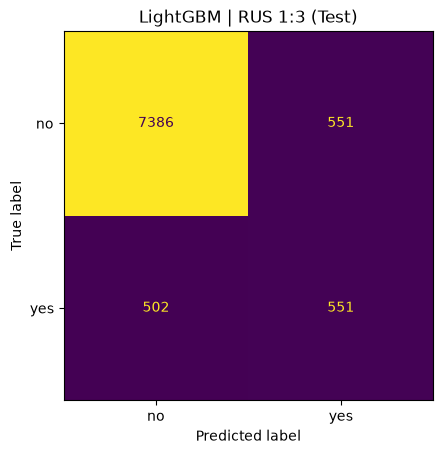

전화할 고객 수 : 1,102명 (전체 8,990명 중 12.3%)
그중 가입 고객 : 551명 → 전화당 가입률 50.0%
찾은 가입 고객 : 전체 가입 고객 1,053명 중 52.3%
무작위로 같은 인원에게 전화했다면 가입 예상 약 129명 → 모델이 약 4.3배


In [69]:
pred_test8 = (proba_test8 >= THRESHOLD).astype(int)

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test8), display_labels=['no', 'yes']).plot(
    colorbar=False, values_format='d')
plt.title('LightGBM | RUS 1:3 (Test)')
plt.show()

r = scores(y_test, proba_test8)
calls = r['TP'] + r['FP']
random_hits = calls * y_test.mean()

print(f"전화할 고객 수 : {calls:,}명 (전체 {len(y_test):,}명 중 {calls / len(y_test):.1%})")
print(f"그중 가입 고객 : {r['TP']:,}명 → 전화당 가입률 {r['TP'] / calls:.1%}")
print(f"찾은 가입 고객 : 전체 가입 고객 {int(y_test.sum()):,}명 중 {r['TP'] / y_test.sum():.1%}")
print(f"무작위로 같은 인원에게 전화했다면 가입 예상 약 {random_hits:.0f}명 → 모델이 약 {r['TP'] / random_hits:.1f}배")

## 8-4. 불균형 처리 전후 비교 (Test)
- 과제의 핵심 질문인 '불균형 처리 전후의 성능 변화'를 Test에서 확인함
- 모델 선택이 아니라 비교 목적이므로, 최종 모델 외의 조합도 Test로 평가함
  - 베이스라인: Logistic Regression, 기존 피처, 처리 없음
  - 최종 모델과 같은 LightGBM·피처, 처리 없음
  - 최종 모델: LightGBM, 새 피처, RUS 1:3

,Accuracy,Precision,Recall,F1,PR-AUC,TP,FP,FN,TN
모델,,,,,,,,,
Baseline LR,0.8917,0.6367,0.1747,0.2742,0.4024,184,105,869,7832
LightGBM (None),0.8948,0.6064,0.2896,0.3920,0.4871,305,198,748,7739
"LightGBM (RUS 1:3, final)",0.8829,0.5000,0.5233,0.5114,0.4673,551,551,502,7386


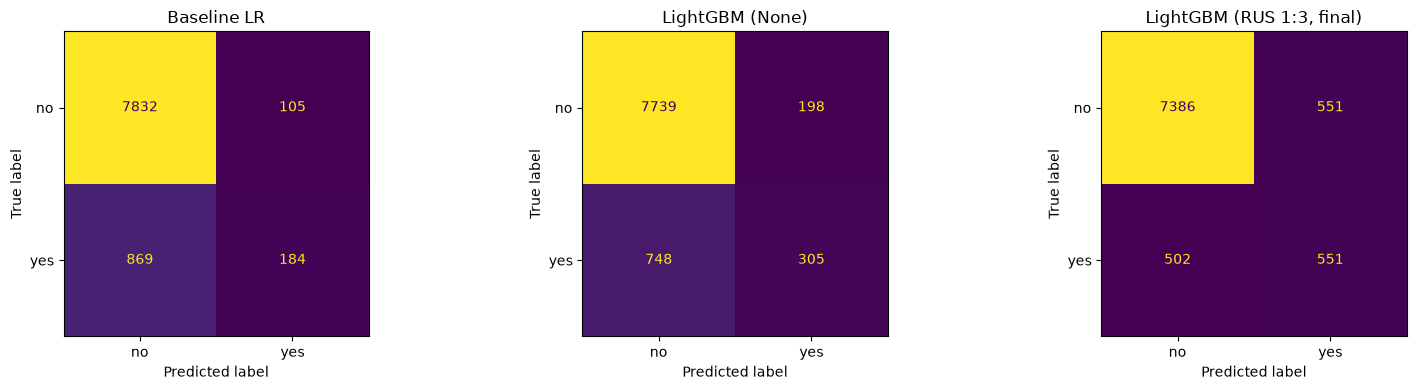

In [70]:
compare8 = {
    'Baseline LR':     (build_pipeline('Logistic Regression'), list(X.columns)),
    'LightGBM (None)':  (make_final_pipe('처리 없음'), FINAL_FEATS),
    'LightGBM (RUS 1:3, final)': (final_pipe, FINAL_FEATS),
}

rows8, probas8 = [], {}
for name, (pipe, cols) in compare8.items():
    if pipe is not final_pipe:                    # 최종 모델은 8-2에서 이미 학습함
        pipe.fit(X_train6[cols], y_train)
    probas8[name] = pipe.predict_proba(X_test6[cols])[:, 1]
    rows8.append({'모델': name, **scores(y_test, probas8[name])})

compare8_df = pd.DataFrame(rows8).set_index('모델')
display(compare8_df)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, name in zip(axes, compare8):
    pred = (probas8[name] >= THRESHOLD).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['no', 'yes']).plot(
        ax=ax, colorbar=False, values_format='d')
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 8-5. 피처 중요도 (최종 모델, Test)
- Permutation Importance: Test에서 변수 하나를 섞었을 때 PR-AUC가 얼마나 떨어지는지
- 최종 모델이 무엇을 근거로 판단하는지 설명하기 위한 분석이며, 결과를 보고 모델을 바꾸지 않음

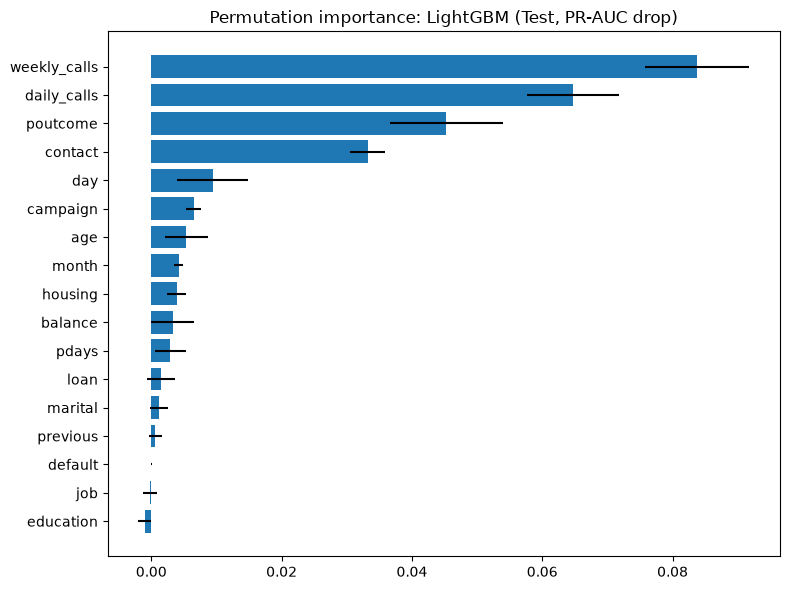

,중요도 평균,표준편차
weekly_calls,0.0838,0.0080
daily_calls,0.0647,0.0071
poutcome,0.0453,0.0086
contact,0.0332,0.0027
day,0.0094,0.0055
campaign,0.0065,0.0011
age,0.0054,0.0033
month,0.0042,0.0007
housing,0.0039,0.0015
balance,0.0033,0.0033


In [71]:
pi8 = permutation_importance(final_pipe, X_te8, y_test, scoring='average_precision',
                             n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)

imp8 = pd.DataFrame({'중요도 평균': pi8.importances_mean, '표준편차': pi8.importances_std},
                    index=X_te8.columns).sort_values('중요도 평균').round(4)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp8.index, imp8['중요도 평균'], xerr=imp8['표준편차'])
ax.set_title('Permutation importance: LightGBM (Test, PR-AUC drop)')
plt.tight_layout()
plt.show()

imp8.sort_values('중요도 평균', ascending=False)

#### 피처 중요도 해석
- 6장에서 추가한 weekly_calls(약 0.084)와 daily_calls(약 0.065)가 1·2위로, 최종 모델은 캠페인 규모 정보를 가장 많이 활용함. 에러바가 다른 변수와 겹치지 않아 일관되게 가장 중요한 변수임.
- 베이스라인부터 중요했던 poutcome(약 0.045)과 contact(약 0.033)가 3·4위로, 이전 캠페인 결과와 연락 방식은 여전히 핵심 신호임.
- 베이스라인에서 1~2위였던 month는 약 0.004로 크게 낮아짐. month가 담던 정보 대부분을 연락 규모 피처가 대신 설명하게 된 것으로, '5월 가입률이 낮다'는 패턴이 계절 효과보다 대량 연락의 영향이었을 가능성을 보여줌. day도 같은 이유로 낮아짐.
- campaign, age, housing, balance, pdays는 0.003~0.007로 작고, job·default·education은 0 근처로 예측에 거의 쓰이지 않음.
- 최종 모델이 캠페인 운영 피처에 크게 의존하므로, 실제 운영에서 계획된 연락 건수를 미리 알 수 없다면 성능이 떨어질 수 있음.

## 8-6. 예측 오차 사례 분석 (Test)
- FN(놓친 가입 고객): 실제로 가입했는데 모델이 가장 낮은 확률을 준 고객
- FP(헛걸음 고객): 실제로 가입하지 않았는데 모델이 가장 높은 확률을 준 고객
- 개별 사례와 함께, 맞힌 고객(TP)·놓친 고객(FN)·헛걸음 고객(FP)의 특성을 그룹으로 비교함

In [72]:
cases = X_te8.copy()
cases['실제'] = y_test.values
cases['가입 확률'] = proba_test8.round(3)
cases['예측'] = pred_test8
cases['오차 유형'] = np.select(
    [(cases['실제'] == 1) & (cases['예측'] == 1),
     (cases['실제'] == 0) & (cases['예측'] == 1),
     (cases['실제'] == 1) & (cases['예측'] == 0)],
    ['TP', 'FP', 'FN'], default='TN')

show_cols = ['age', 'job', 'balance', 'housing', 'loan', 'contact', 'month', 'campaign',
             'poutcome', 'daily_calls', '가입 확률', '실제', '예측', '오차 유형']

print('대표 FN: 실제 가입했지만 확률이 가장 낮았던 고객 5명')
display(cases[cases['오차 유형'] == 'FN'].nsmallest(5, '가입 확률')[show_cols])

print('대표 FP: 가입하지 않았지만 확률이 가장 높았던 고객 5명')
display(cases[cases['오차 유형'] == 'FP'].nlargest(5, '가입 확률')[show_cols])

대표 FN: 실제 가입했지만 확률이 가장 낮았던 고객 5명


,age,job,balance,housing,loan,contact,month,campaign,poutcome,daily_calls,가입 확률,실제,예측,오차 유형
25999,58,retired,2538,yes,no,cellular,nov,2,failure,694,0.024,1,0,FN
28293,48,self-employed,0,no,no,cellular,jan,3,unknown,534,0.029,1,0,FN
26910,50,blue-collar,12519,yes,no,cellular,nov,3,failure,825,0.035,1,0,FN
8644,35,admin.,-87,yes,no,unknown,jun,7,unknown,361,0.036,1,0,FN
33496,37,management,72,yes,yes,cellular,apr,5,failure,625,0.038,1,0,FN


대표 FP: 가입하지 않았지만 확률이 가장 높았던 고객 5명


,age,job,balance,housing,loan,contact,month,campaign,poutcome,daily_calls,가입 확률,실제,예측,오차 유형
40513,42,management,406,yes,no,cellular,jul,1,success,40,0.966,0,1,FP
44184,60,services,739,no,no,cellular,jul,1,success,18,0.963,0,1,FP
42367,25,student,304,no,no,cellular,nov,1,success,13,0.959,0,1,FP
42482,26,services,12,no,no,cellular,dec,4,success,6,0.959,0,1,FP
42521,34,admin.,303,no,no,cellular,dec,3,success,13,0.958,0,1,FP


In [73]:
# 그룹 비교: 맞힌 가입 고객(TP) vs 놓친 가입 고객(FN) vs 헛걸음 고객(FP)
group = cases[cases['오차 유형'].isin(['TP', 'FN', 'FP'])].groupby('오차 유형')

summary8 = pd.DataFrame({
    '고객 수':                group.size(),
    '평균 나이':              group['age'].mean().round(1),
    '잔고 중앙값':            group['balance'].median(),
    '하루 연락 건수 중앙값':   group['daily_calls'].median(),
    '이전 캠페인 성공 비율':   group['poutcome'].apply(lambda s: (s == 'success').mean()).round(3),
    '이전 연락 없음 비율':     group['pdays'].apply(lambda s: (s == -1).mean()).round(3),
    '연락 방식 unknown 비율': group['contact'].apply(lambda s: (s == 'unknown').mean()).round(3),
    '5월 연락 비율':          group['month'].apply(lambda s: (s == 'may').mean()).round(3),
}).loc[['TP', 'FN', 'FP']]
summary8

,고객 수,평균 나이,잔고 중앙값,하루 연락 건수 중앙값,이전 캠페인 성공 비율,이전 연락 없음 비율,연락 방식 unknown 비율,5월 연락 비율
오차 유형,,,,,,,,
TP,551,42.7,902.0,19.0,0.343,0.450,0.011,0.082
FN,502,41.4,475.5,346.0,0.008,0.791,0.185,0.275
FP,551,42.0,913.0,25.0,0.152,0.579,0.031,0.076


## 8-7. 최종 평가 종합
#### 최종 성능 (Test)
- 최종 모델: LightGBM + daily·weekly + RUS 1:3, 임계값 0.5
- Test: Accuracy 0.883, Precision 0.500, Recall 0.523, F1 0.511 (Validation F1 0.509와 비교해 +0.003으로 거의 같음)
- Validation과 Test 성능이 거의 같아, 2~7장에서 Validation으로 내린 결정들이 새로운 데이터에서도 유효함을 확인함

#### 불균형 처리 전후 (Test)
- 베이스라인 LR(기존 피처, 처리 없음) F1 0.274 → 최종 모델 F1 0.511 (약 1.9배)
- 같은 LightGBM의 처리 없음 대비: Recall 0.290 → 0.523, Precision 0.606 → 0.500
  - 개선: 찾은 가입 고객 305명 → 551명 (+246명)
  - 부작용: 헛걸음 통화 198명 → 551명 (+353명), PR-AUC 0.487 → 0.467로 소폭 하락
  - 3장의 결론과 같이, RUS는 고객을 줄 세우는 능력보다 '가입'으로 판단하는 기준을 낮추는 효과가 큼

#### 마케팅 관점
- 전체의 12.3%인 1,102명에게 전화해 551명 가입 (전화당 가입률 50.0%, 무작위 대비 약 4.3배)
  - 무작위로 같은 인원에게 전화했다면 가입 예상 약 129명
- 전체 가입 고객(1,053명)의 52.3%를 찾음

#### 피처 중요도
- 최종 모델이 가장 많이 의존한 변수: weekly_calls, daily_calls, poutcome (다음으로 contact)
- 베이스라인에서 중요했던 month는 연락 규모 피처에 정보가 흡수되어 중요도가 크게 낮아짐

#### 오분류 분석
- 놓친 가입 고객(FN, 502명): 대량 연락일에 연락받은 고객이 대부분이고(하루 연락 건수 중앙값 346건, 맞힌 고객은 19건), 이전 캠페인 성공 이력이 거의 없음(0.8%, 맞힌 고객 34.3%). 이전 연락이 없는 고객 79.1%, 연락 방식 unknown 18.5%, 5월 연락 27.5%로, 모델이 '가입 가능성이 낮은 조건'으로 배운 특징을 가진 가입 고객들임
- 헛걸음 고객(FP, 551명): 소수 선별 연락일(중앙값 25건)에 연락받고 이전 캠페인 성공 비율이 15.2%로, 특징이 맞힌 가입 고객(TP)과 매우 비슷함. 현재 데이터의 정보만으로는 가입 고객과 구분하기 어려운 고객들임

#### 한계
- 최종 모델이 캠페인 운영 피처(weekly_calls, daily_calls)에 크게 의존하므로, 실제 운영에서 '계획된 연락 건수'를 미리 알 수 없다면 성능이 떨어질 수 있으며, 이 피처는 시기 효과를 일부 담고 있을 수 있음
- 반복 고객이 Train과 Test에 나뉘어 들어갔을 가능성이 있음
- 비즈니스 비용(통화 비용, 가입 이익)이 반영되지 않은 임계값 0.5 기준 결과임